---

# Tugas Besar 2 IF3170 Inteligensi Artifisial


---

## Group 28

- Varistha Devi (1524135)
- Mirza Tsabita Wafa'ana (13524114)
- Eliana Natalie Widjojo (13524116)
- A. Rinofaros (13524138)
- Safira Berlianti (13524128)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Proyek ini merupakan bagian dari Tugas Besar 2 mata kuliah IF3170 Inteligensi Artifisial yang berfokus pada penerapan algoritma machine learning untuk memprediksi pembatalan reservasi hotel. Dalam proyek ini, kami mengimplementasikan lima algoritma klasifikasi dari awal (from scratch), yaitu K-Nearest Neighbors (KNN), Decision Tree Learning (CART), Logistic Regression, Support Vector Machine (SVM), dan Naive Bayes.

Proses pengerjaan mencakup eksplorasi dan pengolahan data, implementasi algoritma, pelatihan model, evaluasi performa, serta pencarian hyperparameter terbaik. Selain membandingkan performa kelima algoritma, kami juga membandingkan hasil implementasi from scratch dengan implementasi yang tersedia pada library scikit-learn.

## Aim

Tujuan utama proyek ini adalah membangun model klasifikasi yang mampu memprediksi apakah suatu reservasi hotel akan dibatalkan atau tidak berdasarkan informasi yang tersedia saat pemesanan.

## Metric

Metrik utama yang digunakan untuk mengevaluasi dan memilih model adalah Macro F1-Score. Metrik ini dipilih karena distribusi kelas pada dataset tidak sepenuhnya seimbang, dengan sekitar 67% reservasi tidak dibatalkan dan 33% reservasi dibatalkan.

Selain Macro F1-Score, kami menggunakan Accuracy, Macro Precision, Macro Recall, dan confusion matrix sebagai metrik pendukung. Metrik-metrik tersebut digunakan untuk melihat performa model secara lebih menyeluruh, termasuk jenis kesalahan prediksi yang dihasilkan.

## Dataset

Dataset yang digunakan merupakan data reservasi hotel yang disediakan dalam kompetisi Kaggle untuk Tugas Besar 2 IF3170 Inteligensi Artifisial. Dataset terdiri atas 27.373 data training berlabel dan 6.844 data test tanpa label.

Setiap observasi berisi informasi mengenai reservasi hotel, seperti jumlah tamu, durasi menginap, waktu pemesanan sebelum kedatangan, tanggal kedatangan, jenis kamar, paket makanan, saluran pemesanan, riwayat reservasi pelanggan, tarif kamar, dan jumlah permintaan khusus.

Variabel target yang digunakan adalah is_canceled, dengan nilai 0 menunjukkan reservasi yang tidak dibatalkan dan nilai 1 menunjukkan reservasi yang dibatalkan.

## Approach

Pengerjaan proyek diawali dengan eksplorasi data untuk memahami karakteristik fitur, distribusi target, serta permasalahan kualitas data. Selanjutnya, dilakukan data cleaning untuk menangani missing values, memperbaiki tipe data, dan mengidentifikasi nilai yang tidak valid. Nilai kosong pada fitur numerik ditangani menggunakan median, sedangkan fitur kategorikal menggunakan modus yang dihitung dari data training.

Pada tahap transformasi, kami menggunakan RobustScaler untuk fitur numerik dan One-Hot Encoding untuk fitur kategorikal. Preprocessing tersebut digunakan oleh KNN, Logistic Regression, dan SVM, sedangkan CART menggunakan fitur numerik tanpa scaling. Khusus Naive Bayes, fitur numerik diubah menjadi kategori melalui diskretisasi, sementara fitur dengan jumlah nilai unik yang sedikit dipertahankan sebagai kategori asli.

Setelah preprocessing, kelima algoritma diimplementasikan dan dilatih menggunakan konfigurasi baseline. Hasil prediksi kemudian dievaluasi pada validation set menggunakan Macro F1-Score sebagai metrik utama.

Untuk meningkatkan performa, kami melakukan hyperparameter tuning menggunakan Stratified K-Fold Cross-Validation. Preprocessing dilakukan secara terpisah pada setiap fold untuk mengurangi risiko data leakage. Konfigurasi terbaik kemudian digunakan untuk melatih kembali model pada seluruh development training dan dievaluasi pada holdout validation.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
# ============================================================
# REPOSITORY SETUP
# ============================================================

import os
import sys
import subprocess
import importlib
import random
import time
import inspect
import itertools
import tempfile
import pickle
from pathlib import Path

# jika ingin run di lokal jadikan kode ini komentar sampai yang ditandai di bawah (ada komentar lagi)
from google.colab import userdata

# Repository configuration
REPO_OWNER = "EliWidjojo"
REPO_NAME = "IF3170_G28_HaalinghamJayaAO3"

REPO_URL = (
    f"https://github.com/{REPO_OWNER}/{REPO_NAME}.git"
)
TARGET_PATH = Path("/content") / REPO_NAME

# Secure authentication
# Token baru diambil dari Colab Secrets.

github_token = userdata.get("GITHUB_TOKEN")

if not github_token:
    raise RuntimeError(
        "GITHUB_TOKEN belum tersedia di Colab Secrets."
    )

# GIT_ASKPASS menyediakan kredensial hanya ketika Git meminta.
# File script tidak mengandung token.
askpass_script = """#!/bin/sh
case "$1" in
    *Username*) printf '%s\\n' 'x-access-token' ;;
    *Password*) printf '%s\\n' "$GITHUB_TOKEN" ;;
    *) exit 1 ;;
esac
"""

# Clone repository
os.chdir("/content")

if not TARGET_PATH.exists():
    print("Meng-clone repository...")

    with tempfile.TemporaryDirectory() as temp_dir:
        askpass_path = Path(temp_dir) / "git_askpass.sh"
        askpass_path.write_text(askpass_script)
        askpass_path.chmod(0o700)

        git_env = os.environ.copy()
        git_env["GITHUB_TOKEN"] = github_token
        git_env["GIT_ASKPASS"] = str(askpass_path)
        git_env["GIT_TERMINAL_PROMPT"] = "0"

        subprocess.run(
            ["git", "clone", REPO_URL, str(TARGET_PATH)],
            check=True,
            env=git_env
        )

        git_env.pop("GITHUB_TOKEN", None)
        del git_env

    print("Clone berhasil.")
else:
    print("Repository sudah ada, skip clone.")

# Pastikan remote origin tidak menyimpan token lama.
subprocess.run(
    [
        "git", "-C", str(TARGET_PATH),
        "remote", "set-url", "origin", REPO_URL
    ],
    check=True
)

del github_token

# Set working directory
os.chdir(TARGET_PATH)

if str(TARGET_PATH) not in sys.path:
    sys.path.insert(0, str(TARGET_PATH))

importlib.invalidate_caches()

# Ensure Python packages
for folder in [
    "src",
    "src/knn",
    "src/svm",
    "src/naive_bayes",
    "src/log_reg",
    "src/decision_tree"
]:
    folder_path = TARGET_PATH / folder

    if folder_path.exists():
        init_file = folder_path / "__init__.py"
        init_file.touch(exist_ok=True)

print(f"Repository siap: {os.getcwd()}")
# jadikan komentar sampai sini

# ============================================================
# LIBRARY IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
import networkx as nx

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.preprocessing import (
    RobustScaler,
    OneHotEncoder,
    OrdinalEncoder,
    KBinsDiscretizer
)

from sklearn.decomposition import PCA

from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# FROM SCRATCH ALGORITHMS
# ============================================================

from src.knn.knn import KNN
from src.decision_tree.cart import DecisionTreeCART
from src.log_reg.log_reg import LogisticReg
from src.svm.svm import SVM
from src.naive_bayes.nb import NaiveBayes

# ============================================================
# DISPLAY SETTINGS
# ============================================================

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


Repository sudah ada, skip clone.
Repository siap: /content/IF3170_G28_HaalinghamJayaAO3


In [3]:
import ast
import inspect

cart_file = inspect.getfile(DecisionTreeCART)
source = open(cart_file, encoding="utf-8").read()
tree = ast.parse(source)

cart_class = next(
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
    and node.name == "DecisionTreeCART"
)

methods = [
    node.name for node in cart_class.body
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
]

print("Method export_tree_image dalam kelas:",
      "export_tree_image" in methods)

Method export_tree_image dalam kelas: True


## Settings

Paths and shared constants are kept in this class.

In [4]:
class Settings:
    SEED = 42
    DATA_DIR = Path("data")
    OUTPUT_DIR = Path("output")
    TARGET = "is_canceled"
    VALIDATION_SIZE = 0.20
    OUTLIER_IQR_FACTOR = 1.5
    APPLY_PCA = False
    PCA_VARIANCE = 0.95
    APPLY_RANDOM_OVERSAMPLING = False

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [5]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [6]:
train_path = CFG.DATA_DIR / "train.csv"
test_path = CFG.DATA_DIR / "test.csv"

if not train_path.exists():
    raise FileNotFoundError(
        f"File {train_path} tidak ditemukan. Letakkan train.csv di folder data/."
    )
if not test_path.exists():
    raise FileNotFoundError(
        f"File {test_path} tidak ditemukan. Letakkan test.csv di folder data/."
    )

train_df = pd.read_csv(train_path, dtype={"id": str})
test_df = pd.read_csv(test_path, dtype={"id": str})

print(f"Train: {train_df.shape}")
print(f"Test : {test_df.shape}")
display(train_df.head())

Train: (27373, 19)
Test : (6844, 18)


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [7]:
print("Ukuran dataset:", train_df.shape)
print("\nTipe data setiap atribut:")
display(pd.DataFrame({"dtype": train_df.dtypes, "n_unique": train_df.nunique(),}))

print("\nInformasi dataset:")
train_df.info()

print("\nStatistik deskriptif:")
display(train_df.describe(include="all").T)

Ukuran dataset: (27373, 19)

Tipe data setiap atribut:


,dtype,n_unique
id,object,27373
num_adults,float64,5
num_children,float64,6
weekend_nights,int64,8
weekday_nights,int64,18
meal_package,object,4
needs_parking,float64,2
room_category,object,7
days_before_arrival,float64,407
arrival_year,int64,2



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  object 
 13  is_returning_guest        27373 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,27373,27373,57152f82,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_adults,26564.0,NaN,NaN,NaN,1.845242,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,NaN,NaN,NaN,0.117388,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,NaN,NaN,NaN,0.814854,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,NaN,NaN,NaN,2.206517,1.421603,0.0,1.0,2.0,3.0,17.0
meal_package,25613,4,Breakfast,19654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
needs_parking,26291.0,NaN,NaN,NaN,0.0302,0.171142,0.0,0.0,0.0,0.0,1.0
room_category,26371,7,Type B,20447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_before_arrival,26250.0,NaN,NaN,NaN,85.379429,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,NaN,NaN,NaN,2023.820115,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0


In [8]:
NUM_COLS = ["num_adults", "num_children", "weekend_nights", "weekday_nights", "days_before_arrival", "prior_cancellations", "prior_completed_bookings", "nightly_rate_idr", "special_requests"]
CAT_COLS = ["meal_package", "needs_parking", "room_category", "booking_channel", "is_returning_guest", "arrival_year", "arrival_month", "arrival_day"]

## Explore Data

This part covers distributions and relationships between attributes.

In [9]:
# Parameter grid dipakai di semua blok EDA di bawah
GRID_NCOLS = 3
N_NUM = len(NUM_COLS)
NROWS_NUM = (N_NUM + GRID_NCOLS - 1) // GRID_NCOLS
N_CAT = len(CAT_COLS)
NROWS_CAT = (N_CAT + GRID_NCOLS - 1) // GRID_NCOLS

### Distribusi Kelas Target

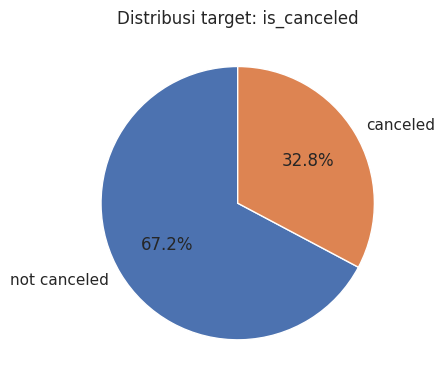

In [10]:
target_counts = train_df[CFG.TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
ax.pie(
    target_counts.values,
    labels=[f"not canceled" if c == 0 else "canceled" for c in target_counts.index],
    autopct="%.1f%%",
    colors=["#4C72B0", "#DD8452"],
    startangle=90,
)
ax.set_title("Distribusi target: is_canceled")
plt.tight_layout()
plt.show()

### Distribusi Fitur Numerik

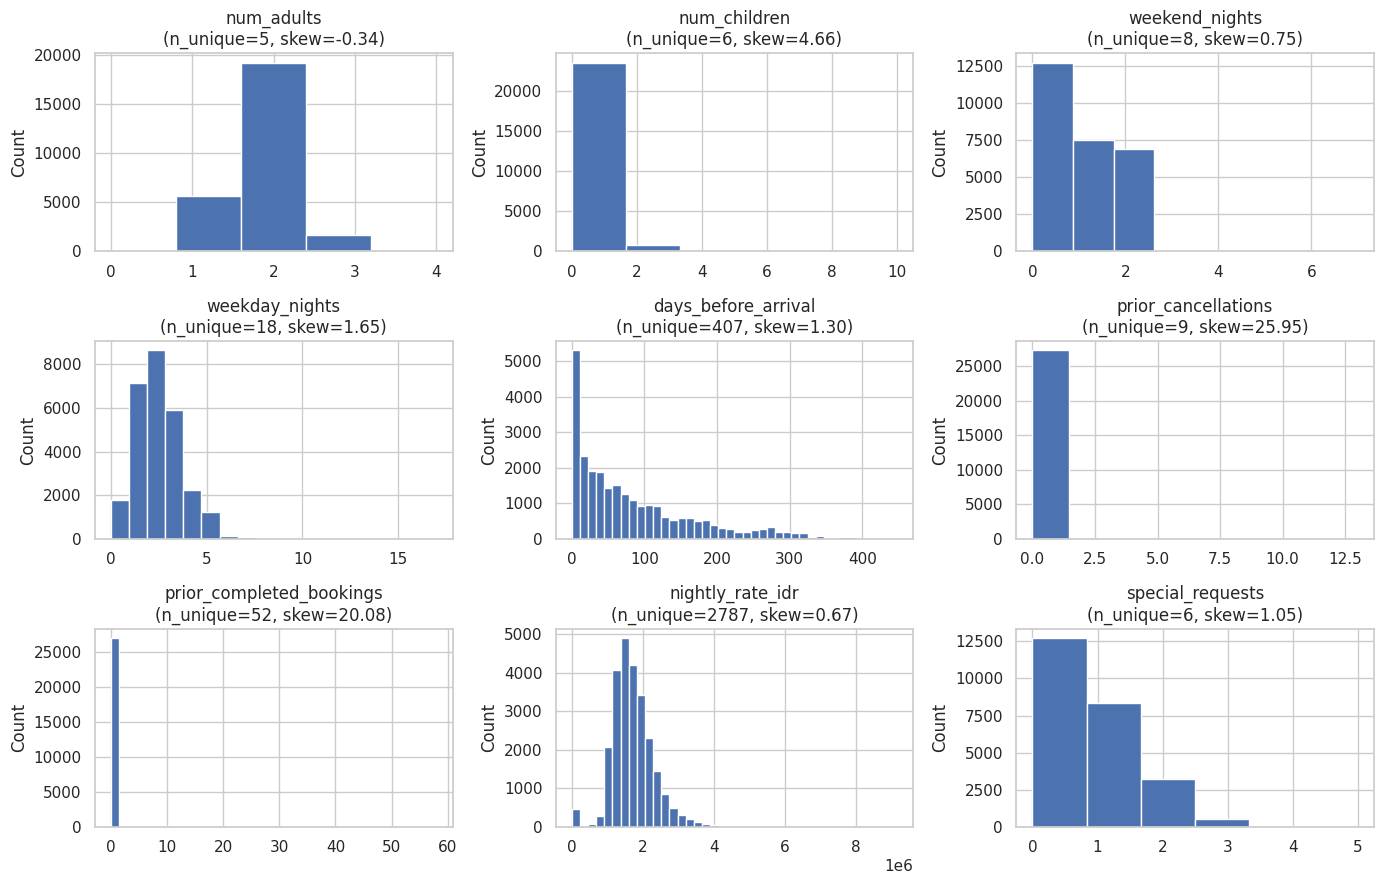

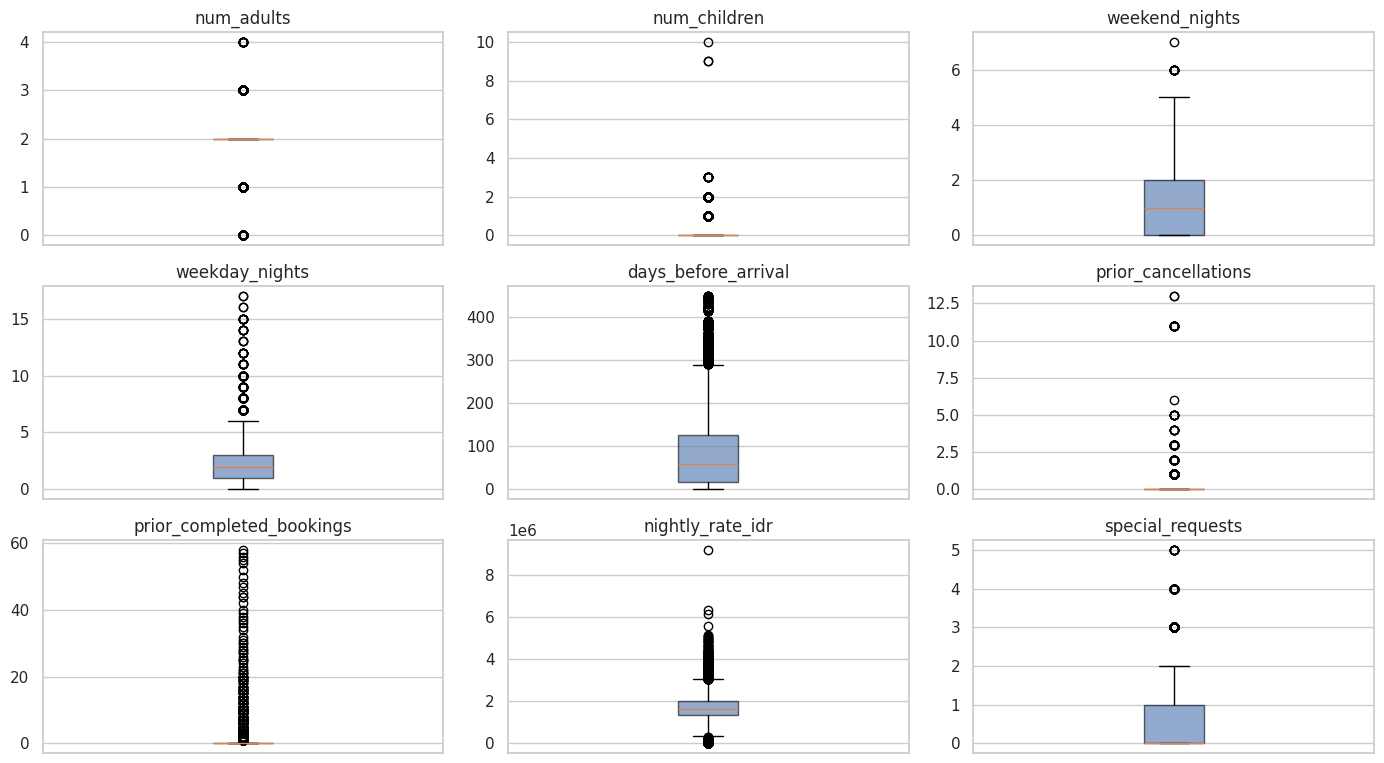

In [11]:
# histogram
fig, axes = plt.subplots(NROWS_NUM, GRID_NCOLS, figsize=(14, 3.0 * NROWS_NUM))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    bins = min(train_df[col].nunique(), 40)
    axes[i].hist(train_df[col].dropna(), bins=bins, color="#4C72B0", edgecolor="white")
    axes[i].set_title(f"{col}\n(n_unique={train_df[col].nunique()}, skew={train_df[col].skew():.2f})")
    axes[i].set_ylabel("Count")

for j in range(N_NUM, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# boxplot
fig, axes = plt.subplots(NROWS_NUM, GRID_NCOLS, figsize=(14, 2.6 * NROWS_NUM))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    axes[i].boxplot(train_df[col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor="#4C72B0", alpha=0.6))
    axes[i].set_title(col)
    axes[i].set_xticks([])

for j in range(N_NUM, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Distribusi Fitur Kategorikal

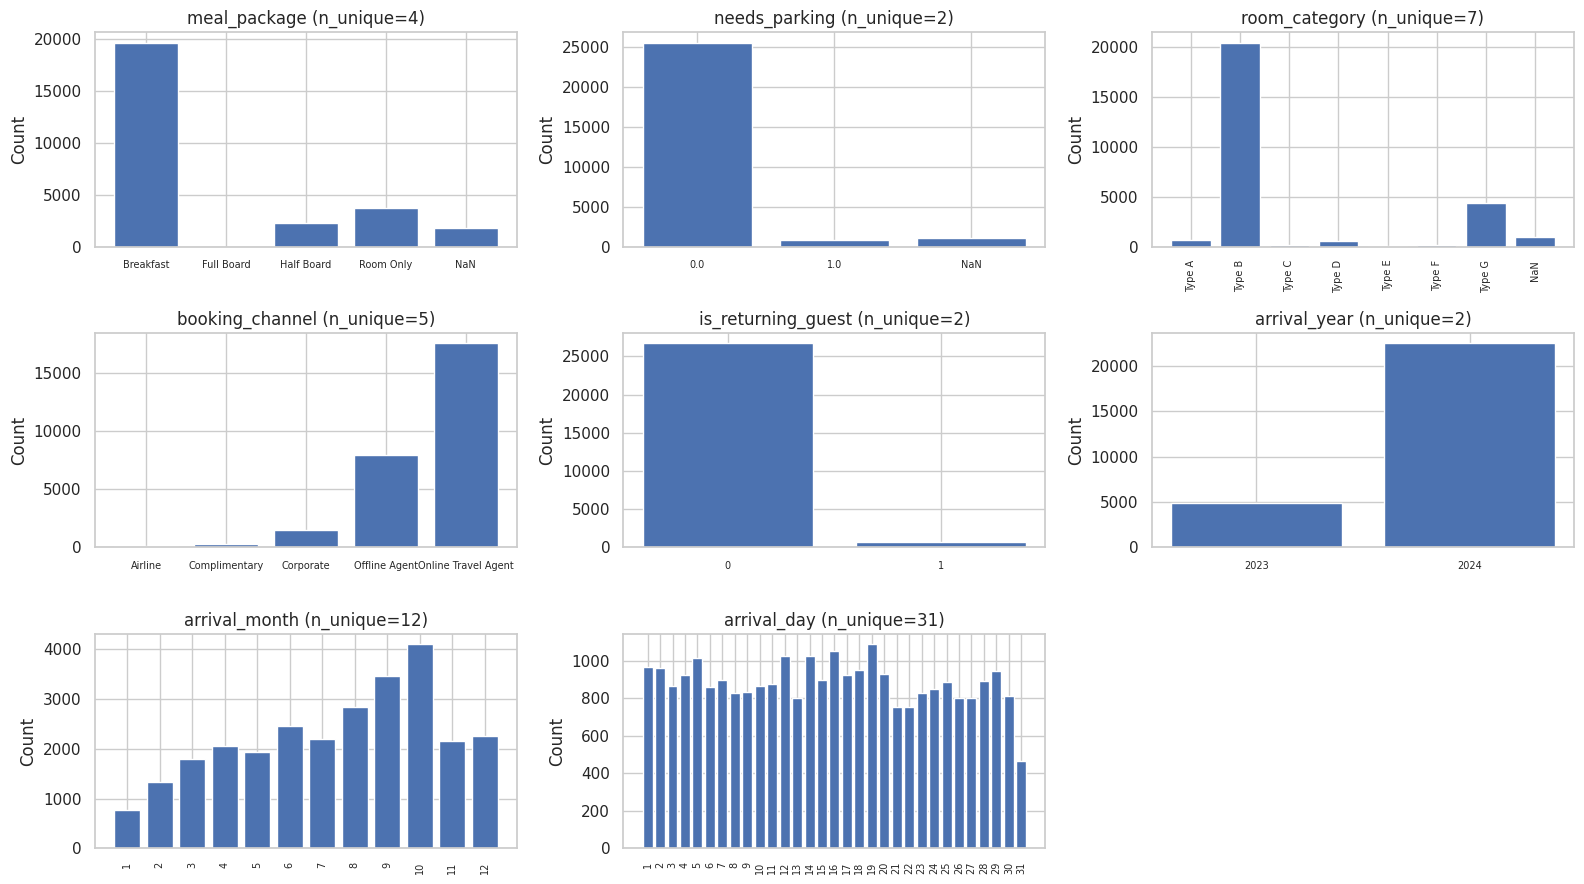

In [12]:
fig, axes = plt.subplots(NROWS_CAT, GRID_NCOLS, figsize=(16, 3.0 * NROWS_CAT))
axes = axes.flatten()

for i, col in enumerate(CAT_COLS):
    vc = train_df[col].value_counts(dropna=False).sort_index()
    x_labels = [str(v) if pd.notna(v) else "NaN" for v in vc.index]
    axes[i].bar(x_labels, vc.values, color="#4C72B0")
    axes[i].set_title(f"{col} (n_unique={train_df[col].nunique()})")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=90 if len(x_labels) > 6 else 0, labelsize=7)

for j in range(N_CAT, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Fitur Numerik vs Target

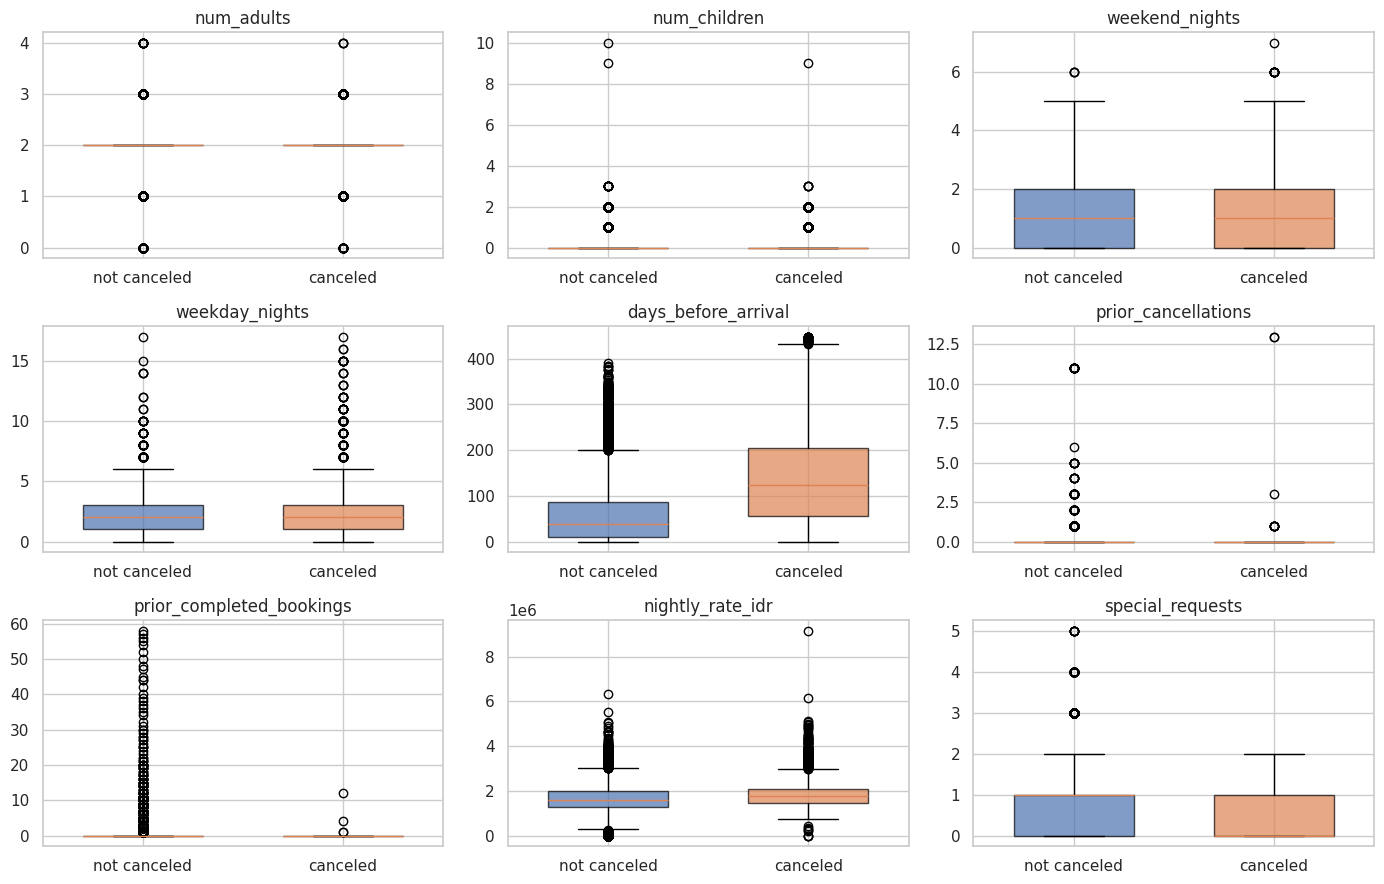

In [13]:
class_labels = sorted(train_df[CFG.TARGET].unique())
label_map = {0: "not canceled", 1: "canceled"}

fig, axes = plt.subplots(NROWS_NUM, GRID_NCOLS, figsize=(14, 3.0 * NROWS_NUM))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    groups = [train_df.loc[train_df[CFG.TARGET] == c, col].dropna() for c in class_labels]
    bp = axes[i].boxplot(groups, patch_artist=True, widths=0.6)
    for patch, color in zip(bp["boxes"], ["#4C72B0", "#DD8452"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[i].set_xticks(range(1, len(class_labels) + 1))
    axes[i].set_xticklabels([label_map.get(c, str(c)) for c in class_labels])
    axes[i].set_title(col)

for j in range(N_NUM, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Fitur Kategorikal vs Target

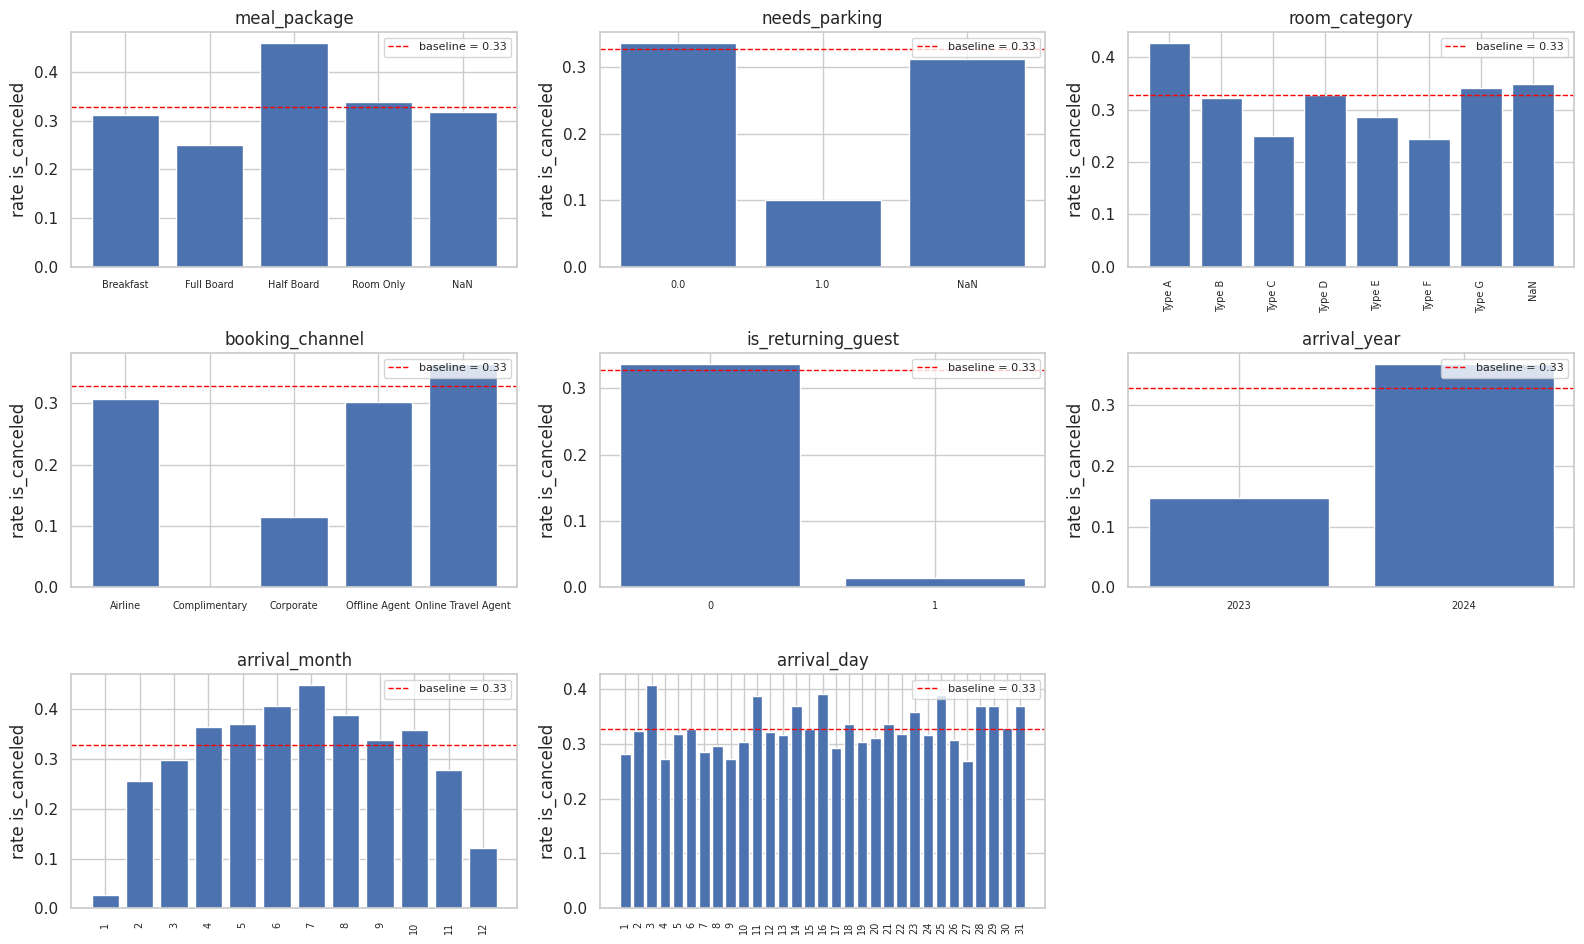

In [14]:
baseline = train_df[CFG.TARGET].mean()

fig, axes = plt.subplots(NROWS_CAT, GRID_NCOLS, figsize=(16, 3.2 * NROWS_CAT))
axes = axes.flatten()

for i, col in enumerate(CAT_COLS):
    rate = train_df.groupby(col, dropna=False)[CFG.TARGET].mean().sort_index()
    x_labels = [str(v) if pd.notna(v) else "NaN" for v in rate.index]
    axes[i].bar(x_labels, rate.values, color="#4C72B0")
    axes[i].axhline(baseline, color="red", linestyle="--", linewidth=1,
                    label=f"baseline = {baseline:.2f}")
    axes[i].set_title(col)
    axes[i].set_ylabel(f"rate {CFG.TARGET}")
    axes[i].legend(fontsize=8, loc="upper right")
    axes[i].tick_params(axis="x", rotation=90 if len(x_labels) > 6 else 0, labelsize=7)

for j in range(N_CAT, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Korelasi Antar Fitur Numerik

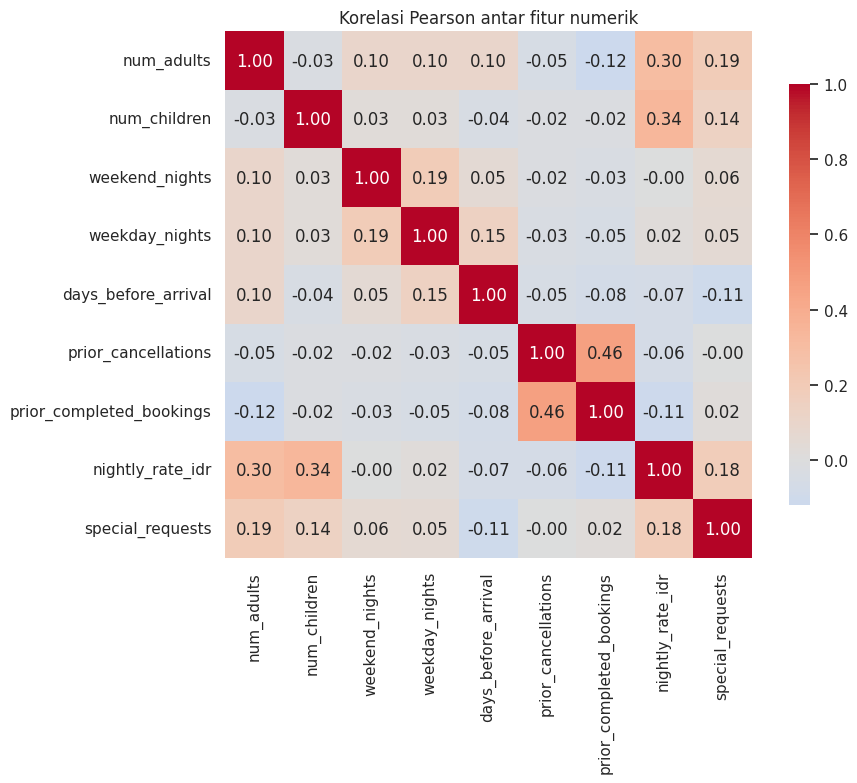

Korelasi:
prior_cancellations       prior_completed_bookings    0.464
num_children              nightly_rate_idr            0.339
num_adults                nightly_rate_idr            0.300
weekend_nights            weekday_nights              0.189
num_adults                special_requests            0.187
nightly_rate_idr          special_requests            0.183
weekday_nights            days_before_arrival         0.150
num_children              special_requests            0.136
num_adults                prior_completed_bookings    0.120
prior_completed_bookings  nightly_rate_idr            0.114
days_before_arrival       special_requests            0.106
num_adults                weekday_nights              0.103
                          days_before_arrival         0.100
                          weekend_nights              0.099
days_before_arrival       prior_completed_bookings    0.076
                          nightly_rate_idr            0.066
prior_cancellations       nigh

In [15]:
corr_matrix = train_df[NUM_COLS].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Korelasi Pearson antar fitur numerik")
plt.tight_layout()
plt.show()

corr_abs = corr_matrix.abs()
mask_upper = np.triu(np.ones_like(corr_abs, dtype=bool), k=1)
top_pairs = corr_abs.where(mask_upper).stack().sort_values(ascending=False)
print("Korelasi:")
print(top_pairs.round(3).to_string())

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [16]:
print("=== Missing values per kolom ===")
train_missing = train_df.isna().sum().to_frame("train")
test_missing = test_df.isna().sum().to_frame("test")
missing_summary = train_missing.join(test_missing, how="outer")
missing_summary["train_pct"] = (missing_summary["train"] / len(train_df) * 100).round(2)
missing_summary["test_pct"] = (missing_summary["test"] / len(test_df) * 100).round(2)
display(
    missing_summary[missing_summary[["train", "test"]].sum(axis=1) > 0]
    .sort_values("train", ascending=False)
)

missing_per_row = train_df.isna().sum(axis=1)

print("\nDistribusi jumlah missing per baris (train):")
display(missing_per_row.value_counts().sort_index().to_frame("count"))
print(f"Max missing per baris: {missing_per_row.max()}")

# Berapa baris dengan missing "berat"?
for th in [3, 5, 7]:
    n = (missing_per_row >= th).sum()
    print(f"Baris dengan ≥{th} missing: {n} ({n/len(train_df)*100:.2f}%)")

print("\n=== Duplikasi ===")
print(f"Duplikasi baris train: {train_df.duplicated().sum()}")
print(f"Duplikasi baris test : {test_df.duplicated().sum()}")
print(f"id unik di train: {train_df['id'].is_unique}")
print(f"id unik di test : {test_df['id'].is_unique}")
print(f"id overlap train-test: {len(set(train_df['id']) & set(test_df['id']))}")

print("\n=== Dtype train vs test ===")
common_cols = [c for c in train_df.columns if c != CFG.TARGET]
dtype_match = train_df[common_cols].dtypes == test_df[common_cols].dtypes
n_match, n_total = int(dtype_match.sum()), len(dtype_match)
if dtype_match.all():
    print(f"{n_match}/{n_total} kolom identik")
else:
    print(f"{n_match}/{n_total} kolom match")
    display(dtype_match[~dtype_match].to_frame("match"))

print("\n=== Kategori unseen di test ===")
unseen_report = {}
for col in CAT_COLS:
    unseen = set(test_df[col].dropna().unique()) - set(train_df[col].dropna().unique())
    if unseen:
        unseen_report[col] = sorted(unseen)

if unseen_report:
    print(f"{len(unseen_report)}/{len(CAT_COLS)} fitur punya kategori baru di test:")
    for col, vals in unseen_report.items():
        print(f"  - {col}: {vals}")
else:
    print(f"{len(CAT_COLS)}/{len(CAT_COLS)} fitur: semua kategori test ada di train")


=== Missing values per kolom ===


,train,test,train_pct,test_pct
num_children,3035,747.0,11.09,10.91
special_requests,2500,593.0,9.13,8.66
nightly_rate_idr,2038,540.0,7.45,7.89
meal_package,1760,442.0,6.43,6.46
days_before_arrival,1123,290.0,4.10,4.24
needs_parking,1082,247.0,3.95,3.61
room_category,1002,242.0,3.66,3.54
num_adults,809,180.0,2.96,2.63



Distribusi jumlah missing per baris (train):


,count
0,16636
1,8478
2,1933
3,301
4,23
5,2


Max missing per baris: 5
Baris dengan ≥3 missing: 326 (1.19%)
Baris dengan ≥5 missing: 2 (0.01%)
Baris dengan ≥7 missing: 0 (0.00%)

=== Duplikasi ===
Duplikasi baris train: 0
Duplikasi baris test : 0
id unik di train: True
id unik di test : True
id overlap train-test: 0

=== Dtype train vs test ===
18/18 kolom identik

=== Kategori unseen di test ===
8/8 fitur: semua kategori test ada di train


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [17]:
if CFG.TARGET not in train_df.columns:
    raise KeyError(f"Kolom target '{CFG.TARGET}' tidak ditemukan di train.csv.")

# Split dengan stratifikasi agar proporsi target terjaga
train_set, val_set = train_test_split(
    train_df,
    test_size=CFG.VALIDATION_SIZE,
    random_state=CFG.SEED,
    stratify=train_df[CFG.TARGET]
)

train_set = train_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)

print(f"Training set   : {train_set.shape}")
print(f"Validation set : {val_set.shape}")

# Ringkasan distribusi target
split_summary = pd.DataFrame({
    "train_count": train_set[CFG.TARGET].value_counts().sort_index(),
    "train_pct": (train_set[CFG.TARGET].value_counts(normalize=True).sort_index() * 100).round(2),
    "val_count": val_set[CFG.TARGET].value_counts().sort_index(),
    "val_pct": (val_set[CFG.TARGET].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(split_summary)

Training set   : (21898, 19)
Validation set : (5475, 19)


,train_count,train_pct,val_count,val_pct
is_canceled,,,,
0,14723,67.23,3681,67.23
1,7175,32.77,1794,32.77


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [18]:
target_col = CFG.TARGET
id_col = "id"

# Simpan ID
train_ids = train_set[id_col].copy()
val_ids = val_set[id_col].copy()
test_ids = test_df[id_col].copy()

# Pisahkan fitur dan target
y_train = train_set[target_col].copy()
y_val = val_set[target_col].copy()

X_train = train_set.drop(columns=[id_col, target_col]).copy()
X_val = val_set.drop(columns=[id_col, target_col]).copy()
X_test = test_df.drop(columns=[id_col]).copy()

# Samakan urutan fitur
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

# Simpan data sebelum preprocessing untuk eksperimen CV
X_train_raw = X_train.copy()
X_val_raw = X_val.copy()
X_test_raw = X_test.copy()

y_train_raw = y_train.copy()
y_val_raw = y_val.copy()

print("Training  :", X_train.shape)
print("Validation:", X_val.shape)
print("Test      :", X_test.shape)

Training  : (21898, 17)
Validation: (5475, 17)
Test      : (6844, 17)


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [19]:
# Kolom yang seluruh nilainya kosong dan tidak memberikan informasi
all_missing_cols = X_train.columns[X_train.isna().all()].tolist()
print("Kolom seluruhnya missing:", all_missing_cols)

X_train.drop(columns=all_missing_cols, inplace=True)
X_val.drop(columns=all_missing_cols, inplace=True)
X_test.drop(columns=all_missing_cols, inplace=True)

# Nilai kosong pada kolom lain tidak diisi secara manual di sini.
missing_train = X_train.isna().sum()
display(missing_train[missing_train > 0].sort_values(ascending=False).to_frame("missing_train"))

Kolom seluruhnya missing: []


,missing_train
num_children,2426
special_requests,2015
nightly_rate_idr,1622
meal_package,1403
needs_parking,885
days_before_arrival,877
room_category,810
num_adults,636


### Duplicates

This part covers repeated records.

In [20]:
duplicate_train = train_set.duplicated().sum()
print("Duplikasi baris training   :", duplicate_train)
print("Duplikasi kombinasi fitur training:", X_train.duplicated().sum())

Duplikasi baris training   : 0
Duplikasi kombinasi fitur training: 41


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [21]:
non_negative_cols = [
    "num_adults", "num_children", "weekend_nights",
    "weekday_nights", "days_before_arrival",
    "prior_cancellations", "prior_completed_bookings",
    "nightly_rate_idr", "special_requests"
]

numeric_candidates = non_negative_cols + [
    "needs_parking", "arrival_year",
    "arrival_month", "arrival_day", "is_returning_guest"
]

def correct_data_errors(df):
    df = df.copy()

    # Bersihkan spasi kategori
    for col in df.select_dtypes(include=["object", "category"]).columns:
        df[col] = df[col].str.strip()

    # Konversi tipe numerik
    for col in numeric_candidates:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Nilai negatif tidak valid
    for col in non_negative_cols:
        if col in df.columns:
            df.loc[df[col] < 0, col] = np.nan

    # Fitur biner
    for col in ["needs_parking", "is_returning_guest"]:
        if col in df.columns:
            df.loc[~df[col].isin([0, 1]), col] = np.nan

    # Rentang tanggal
    if "arrival_month" in df.columns:
        df.loc[~df["arrival_month"].between(1, 12), "arrival_month"] = np.nan

    if "arrival_day" in df.columns:
        df.loc[~df["arrival_day"].between(1, 31), "arrival_day"] = np.nan

    return df


X_train = correct_data_errors(X_train)
X_val = correct_data_errors(X_val)
X_test = correct_data_errors(X_test)

print("Missing values setelah cleaning:")
display(
    X_train.isna().sum()
    .loc[lambda x: x > 0]
    .to_frame("missing_count")
)

Missing values setelah cleaning:


,missing_count
num_adults,636
num_children,2426
meal_package,1403
needs_parking,885
room_category,810
days_before_arrival,877
nightly_rate_idr,1622
special_requests,2015


### Outliers

This part covers values far from the rest of the data.

In [22]:
continuous_for_iqr = ["nightly_rate_idr", "days_before_arrival"]
outlier_summary = []

for col in continuous_for_iqr:
    if col not in X_train.columns: continue
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - CFG.OUTLIER_IQR_FACTOR * iqr
    upper = q3 + CFG.OUTLIER_IQR_FACTOR * iqr
    n_outliers = ((X_train[col] < lower) | (X_train[col] > upper)).sum()

    outlier_summary.append({
        "feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "n_outliers": n_outliers, "outlier_pct": (n_outliers / len(X_train) * 100)
    })

display(pd.DataFrame(outlier_summary))
# Nilai outlier DIPERTAHANKAN (tidak di-clip)

,feature,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,outlier_pct
0,nightly_rate_idr,1339000.0,2022000.0,683000.0,314500.0,3046500.0,889,4.059731
1,days_before_arrival,17.0,125.0,108.0,-145.0,287.0,755,3.447803


## Construct Data

Construction derives attributes and transforms values for modeling.

### Imputation

In [23]:
all_missing_cols = X_train.columns[X_train.isna().all()].tolist()

for df in [X_train, X_val, X_test]:
    df.drop(columns=all_missing_cols, inplace=True)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

for df in [X_train, X_val, X_test]:
    df[numeric_cols] = df[numeric_cols].fillna(X_train[numeric_cols].median())
    df[categorical_cols] = df[categorical_cols].fillna(X_train[categorical_cols].mode().iloc[0])

print("Missing setelah imputasi:", X_train.isna().sum().sum())

Missing setelah imputasi: 0


### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [24]:
def engineer_features(df):
    df = df.copy()

    # Fitur agregat
    df["total_guests"] = df["num_adults"] + df["num_children"]
    df["total_nights"] = df["weekend_nights"] + df["weekday_nights"]
    df["total_cost"] = df["nightly_rate_idr"] * df["total_nights"]

    # Fitur historis
    df["historical_cancel_rate"] = ((df["prior_cancellations"] + 1) / (df["prior_cancellations"] + df["prior_completed_bookings"] + 2))

    # Representasi siklik bulan
    month = pd.to_numeric(df["arrival_month"], errors="coerce")
    df["arrival_month_sin"] = np.sin(2 * np.pi * month / 12)
    df["arrival_month_cos"] = np.cos(2 * np.pi * month / 12)

    # Hari dalam minggu berdasarkan tanggal kedatangan
    date = pd.to_datetime(
        df[["arrival_year", "arrival_month", "arrival_day"]].rename(
            columns={
                "arrival_year": "year",
                "arrival_month": "month",
                "arrival_day": "day"
            }
        ),
        errors="coerce"
    )

    df["day_of_week"] = date.dt.dayofweek

    return df


# # Feature engineering
# X_train = engineer_features(X_train)
# X_val = engineer_features(X_val)
# X_test = engineer_features(X_test)

# # Imputasi day_of_week menggunakan modus training
# mode_dow = X_train["day_of_week"].mode().iloc[0]

# for df in [X_train, X_val, X_test]:
#     df["day_of_week"] = df["day_of_week"].fillna(mode_dow)

#     # Hapus tanggal mentah yang sudah direpresentasikan
#     df.drop(columns=["arrival_month", "arrival_day"], inplace=True)

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [25]:
# codenya di bawah sekalian pipelinening

### Encoding

This part covers the numeric representation of categorical attributes.

In [26]:
# codenya di bawah sekalian pipelinening

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [27]:
# if CFG.APPLY_PCA:
#     dimensionality_reducer = PCA(
#         n_components=CFG.PCA_VARIANCE,
#         random_state=CFG.SEED
#     )
# else:
#     dimensionality_reducer = None

# print("PCA aktif:", dimensionality_reducer is not None)

## Class Balance

This part covers the proportion of each class in the training data.

In [28]:
balance_df = pd.DataFrame({
    "Train Count": y_train.value_counts().sort_index(),
    "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "Val Count": y_val.value_counts().sort_index(),
    "Val (%)": (y_val.value_counts(normalize=True).sort_index() * 100).round(2)
})

balance_df.index = balance_df.index.map({0: "Not Canceled (0)", 1: "Canceled (1)"})
display(balance_df)
print("\nTidak dilakukan resampling pada baseline.")

,Train Count,Train (%),Val Count,Val (%)
is_canceled,,,,
Not Canceled (0),14723,67.23,3681,67.23
Canceled (1),7175,32.77,1794,32.77



Tidak dilakukan resampling pada baseline.


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [29]:
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

for name, df in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    assert not df.isna().any().any(), f"{name} masih memiliki missing value"
    print(f"{name}: {df.shape}")

assert y_train.isin([0, 1]).all()
assert y_val.isin([0, 1]).all()

Train: (21898, 17)
Validation: (5475, 17)
Test: (6844, 17)


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [30]:
# Preparation Pipeline
NUM_CONTINUOUS = X_train.select_dtypes(include=np.number).columns.tolist()
CATEGORICAL_FEATURES = X_train.select_dtypes(exclude=np.number).columns.tolist()

# KNN, Logistic Regression, dan SVM
preprocessor_scaled = ColumnTransformer([
    ("num", RobustScaler(), NUM_CONTINUOUS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     CATEGORICAL_FEATURES)
])

# CART tanpa scaling
preprocessor_unscaled = ColumnTransformer([
    ("num", "passthrough", NUM_CONTINUOUS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     CATEGORICAL_FEATURES)
])

X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_val_scaled = preprocessor_scaled.transform(X_val)
X_test_scaled = preprocessor_scaled.transform(X_test)

X_train_unscaled = preprocessor_unscaled.fit_transform(X_train)
X_val_unscaled = preprocessor_unscaled.transform(X_val)
X_test_unscaled = preprocessor_unscaled.transform(X_test)

print("Scaled:", X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)
print("Unscaled:", X_train_unscaled.shape, X_val_unscaled.shape, X_test_unscaled.shape)

assert X_train_scaled.shape[1] == X_val_scaled.shape[1] == X_test_scaled.shape[1]
assert X_train_unscaled.shape[1] == X_val_unscaled.shape[1] == X_test_unscaled.shape[1]

Scaled: (21898, 30) (5475, 30) (6844, 30)
Unscaled: (21898, 30) (5475, 30) (6844, 30)


In [31]:
# Categorical Naive Bayes Preprocessing
NB_COUNT_FEATURES = [
    "num_children",
    "prior_cancellations",
    "prior_completed_bookings"
]

NB_DIRECT_FEATURES = [
    col for col in NUM_CONTINUOUS
    if col not in NB_COUNT_FEATURES
    and X_train[col].nunique() <= 5
]

NB_NUMERIC_FEATURES = [
    col for col in NUM_CONTINUOUS
    if col not in NB_COUNT_FEATURES
    and col not in NB_DIRECT_FEATURES
]

def fit_nb_discretization(df, columns, n_bins=5):
    bin_edges = {}

    for col in columns:
        quantiles = df[col].quantile(np.linspace(0, 1, n_bins + 1)).to_numpy(dtype=float)
        edges = np.unique(quantiles)

        if len(edges) < 2:
            edges = np.array([-np.inf, np.inf])
        else:
            edges[0] = -np.inf
            edges[-1] = np.inf

        bin_edges[col] = edges

    return bin_edges

def apply_nb_discretization(df, columns, bin_edges):
    result = pd.DataFrame(index=df.index)

    for col in columns:
        bins = pd.cut(df[col], bins=bin_edges[col], labels=False, include_lowest=True)
        if bins.isna().any():
            raise ValueError(f"Kolom {col} menghasilkan missing saat binning")
        result[col] = bins.map(lambda x: f"bin_{int(x)}")

    return result

def count_to_category(series):
    if series.isna().any():
        raise ValueError("Fitur hitungan masih memiliki NaN")

    if (series < 0).any():
        raise ValueError("Fitur hitungan memiliki nilai negatif")

    return series.apply(
        lambda x:
            "count_0" if x == 0
            else "count_1" if x == 1
            else "count_2" if x == 2
            else "count_3plus"
    )

def apply_count_discretization(df, columns):
    result = pd.DataFrame(index=df.index)

    for col in columns:
        result[col] = count_to_category(df[col])

    return result

# Batas kuantil dipelajari dari training saja
nb_bin_edges = fit_nb_discretization(X_train, NB_NUMERIC_FEATURES, n_bins=5)

def transform_nb(df, bin_edges=None):
    if bin_edges is None:
        bin_edges = nb_bin_edges

    numeric = apply_nb_discretization(df, NB_NUMERIC_FEATURES, bin_edges)
    counts = apply_count_discretization(df, NB_COUNT_FEATURES)
    categorical = df[CATEGORICAL_FEATURES + NB_DIRECT_FEATURES].copy()

    return pd.concat([numeric, counts, categorical], axis=1).astype(str)

X_train_nb = transform_nb(X_train)
X_val_nb = transform_nb(X_val)
X_test_nb = transform_nb(X_test)

print("Naive Bayes:")
print("Train     :", X_train_nb.shape)
print("Validation:", X_val_nb.shape)
print("Test      :", X_test_nb.shape)

assert X_train_nb.columns.equals(X_val_nb.columns)
assert X_train_nb.columns.equals(X_test_nb.columns)

Naive Bayes:
Train     : (21898, 17)
Validation: (5475, 17)
Test      : (6844, 17)


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

In [32]:
model_data = {
    "KNN": (X_train_scaled, X_val_scaled, X_test_scaled),
    "CART": (X_train_unscaled, X_val_unscaled, X_test_unscaled),
    "Logistic Regression": (X_train_scaled, X_val_scaled, X_test_scaled),
    "SVM": (X_train_scaled, X_val_scaled, X_test_scaled),
    "Naive Bayes": (X_train_nb, X_val_nb, X_test_nb)
}

y_train_arr = np.asarray(y_train).ravel()
y_val_arr = np.asarray(y_val).ravel()

for name, (train, val, test) in model_data.items():
    assert len(train) == len(y_train_arr)
    assert len(val) == len(y_val_arr)
    assert len(test) == len(X_test)
    assert train.shape[1] == val.shape[1] == test.shape[1]

    print(f"{name}: {train.shape} | {val.shape} | {test.shape}")

KNN: (21898, 30) | (5475, 30) | (6844, 30)
CART: (21898, 30) | (5475, 30) | (6844, 30)
Logistic Regression: (21898, 30) | (5475, 30) | (6844, 30)
SVM: (21898, 30) | (5475, 30) | (6844, 30)
Naive Bayes: (21898, 17) | (5475, 17) | (6844, 17)


In [33]:
# Penyimpanan hasil baseline dan improvement
baseline_models = {}
baseline_predictions = {}
baseline_results = []

best_models = {}
best_predictions = {}

def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

def evaluate_baseline(name, model, X_train_data, X_val_data):
    print(f"\n=== Baseline {name} ===")

    start = time.perf_counter()
    model.fit(X_train_data, y_train_arr)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = np.asarray(model.predict(X_val_data)).ravel()
    predict_time = time.perf_counter() - start

    metrics = evaluate_model(y_val_arr, y_pred)

    baseline_models[name] = model
    baseline_predictions[name] = y_pred

    baseline_results.append({
        "Model": name,
        **metrics,
        "Fit Time (s)": fit_time,
        "Predict Time (s)": predict_time
    })

    display(pd.Series(metrics, name=name).to_frame("Score"))

    print("\nClassification Report:")
    print(classification_report(
        y_val_arr, y_pred, labels=[0, 1], zero_division=0
    ))

    print("Confusion Matrix:")
    display(pd.DataFrame(
        confusion_matrix(y_val_arr, y_pred, labels=[0, 1]),
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    ))

    print(f"Fit: {fit_time:.2f}s | Predict: {predict_time:.2f}s")

    return model, y_pred, metrics

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [34]:
knn_baseline = KNN(
    k=5,
    distance_metric="euclidean",
    weights="uniform"
)

knn_baseline, knn_pred, knn_metrics = evaluate_baseline(
    "KNN", knn_baseline,
    X_train_scaled, X_val_scaled
)


=== Baseline KNN ===


,Score
Accuracy,0.837991
Precision,0.817406
Recall,0.812080
F1-Score,0.814619



Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.89      0.88      3681
           1       0.76      0.74      0.75      1794

    accuracy                           0.84      5475
   macro avg       0.82      0.81      0.81      5475
weighted avg       0.84      0.84      0.84      5475

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,3266,415
Actual 1,472,1322


Fit: 0.00s | Predict: 44.47s


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [35]:
dt_baseline = DecisionTreeCART(
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=4,
    min_impurity_decrease=1e-10
)

dt_baseline, dt_pred, dt_metrics = evaluate_baseline(
    "CART", dt_baseline,
    X_train_unscaled, X_val_unscaled
)


=== Baseline CART ===


,Score
Accuracy,0.823562
Precision,0.799694
Recall,0.800206
F1-Score,0.799949



Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87      3681
           1       0.73      0.73      0.73      1794

    accuracy                           0.82      5475
   macro avg       0.80      0.80      0.80      5475
weighted avg       0.82      0.82      0.82      5475

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,3195,486
Actual 1,480,1314


Fit: 11.72s | Predict: 0.13s


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [36]:
lr_baseline = LogisticReg(
    learning_rate=0.01,
    n_epochs=200,
    penalty=None,
    lambda1=0.0,
    lambda2=0.0,
    batch_size=256,
    shuffle=True,
    tol=None,
    random_state=CFG.SEED,
    record_history=True
)

lr_baseline, lr_pred, lr_metrics = evaluate_baseline(
    "Logistic Regression", lr_baseline,
    X_train_scaled, X_val_scaled
)

print("Epoch yang dijalankan:", lr_baseline.n_epochs_run)


=== Baseline Logistic Regression ===


,Score
Accuracy,0.798721
Precision,0.777535
Recall,0.750586
F1-Score,0.760756



Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86      3681
           1       0.73      0.61      0.67      1794

    accuracy                           0.80      5475
   macro avg       0.78      0.75      0.76      5475
weighted avg       0.79      0.80      0.79      5475

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,3277,404
Actual 1,698,1096


Fit: 3.44s | Predict: 0.00s
Epoch yang dijalankan: 200


## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [37]:
svm_baseline = SVM(
    kernel="linear",
    C=1.0,
    degree=3,
    gamma="scale",
    coef0=1.0,
    lr=0.01,
    epochs=50,
    max_kernel_samples=2000,
    random_state=CFG.SEED
)

svm_baseline, svm_pred, svm_metrics = evaluate_baseline(
    "SVM", svm_baseline,
    X_train_scaled, X_val_scaled
)

print("Total slack:", svm_baseline.slack_total)


=== Baseline SVM ===


,Score
Accuracy,0.797260
Precision,0.781395
Recall,0.739641
F1-Score,0.753307



Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86      3681
           1       0.75      0.57      0.65      1794

    accuracy                           0.80      5475
   macro avg       0.78      0.74      0.75      5475
weighted avg       0.79      0.80      0.79      5475

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,3338,343
Actual 1,767,1027


Fit: 11.41s | Predict: 0.00s
Total slack: 10641.79177872245


## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [38]:
nb_baseline = NaiveBayes(alpha=1.0)

nb_baseline, nb_pred, nb_metrics = evaluate_baseline(
    "Naive Bayes", nb_baseline,
    X_train_nb, X_val_nb
)

print("Jumlah kelas:", len(nb_baseline.classes))
print("Jumlah fitur:", len(nb_baseline.features))


=== Baseline Naive Bayes ===


,Score
Accuracy,0.759452
Precision,0.727069
Recall,0.712953
F1-Score,0.718695



Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.83      3681
           1       0.65      0.58      0.61      1794

    accuracy                           0.76      5475
   macro avg       0.73      0.71      0.72      5475
weighted avg       0.75      0.76      0.76      5475

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,3121,560
Actual 1,757,1037


Fit: 0.17s | Predict: 0.06s
Jumlah kelas: 2
Jumlah fitur: 17


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

=== Perbandingan Baseline ===


,Model,Accuracy,Precision,Recall,F1-Score,Fit Time (s),Predict Time (s)
0,KNN,0.8380,0.8174,0.8121,0.8146,0.0031,44.4703
1,CART,0.8236,0.7997,0.8002,0.7999,11.7243,0.1334
2,Logistic Regression,0.7987,0.7775,0.7506,0.7608,3.4359,0.0007
3,SVM,0.7973,0.7814,0.7396,0.7533,11.4114,0.0003
4,Naive Bayes,0.7595,0.7271,0.7130,0.7187,0.1712,0.0610


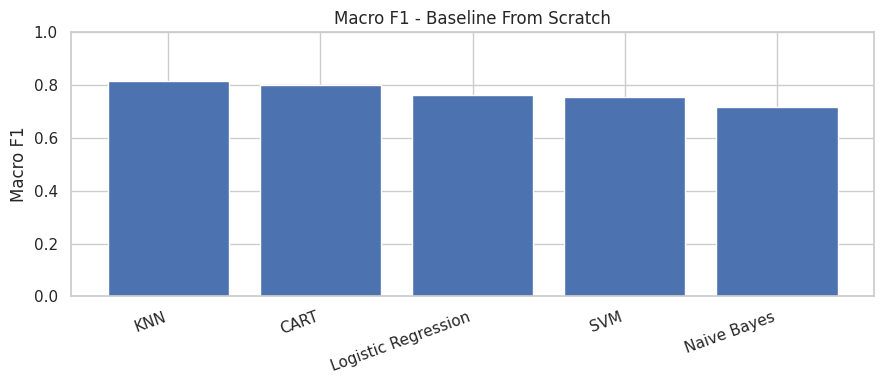

Baseline terbaik: KNN (Macro F1=0.8146)


In [39]:
# Perbandingan 5 Algoritma From Scratch
baseline_comparison_df = (
    pd.DataFrame(baseline_results)
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
)

print("=== Perbandingan Baseline ===")
display(baseline_comparison_df.round(4))

# Grafik Macro F1
plt.figure(figsize=(9, 4))
plt.bar(baseline_comparison_df["Model"], baseline_comparison_df["F1-Score"])

plt.title("Macro F1 - Baseline From Scratch")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_baseline = baseline_comparison_df.iloc[0]

print(
    f"Baseline terbaik: {best_baseline['Model']} "
    f"(Macro F1={best_baseline['F1-Score']:.4f})"
)

baseline_comparison_df.to_csv("baseline_comparison.csv", index=False)

## Improvement (Optional)

#### Shared CV Preprocessor

In [40]:
# Shared preprocessing untuk cross-validation
def prepare_cv_fold(X_tr_raw, X_va_raw, scaled=True):
    X_tr = correct_data_errors(X_tr_raw)
    X_va = correct_data_errors(X_va_raw)

    num_cols = X_tr.select_dtypes(include=np.number).columns.tolist()
    cat_cols = X_tr.select_dtypes(exclude=np.number).columns.tolist()

    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scaled:
        num_steps.append(("scaler", RobustScaler()))

    preprocessor = ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]), cat_cols)
    ])

    train = preprocessor.fit_transform(X_tr)
    val = preprocessor.transform(X_va)

    return (
        np.asarray(train, dtype=np.float64),
        np.asarray(val, dtype=np.float64)
    )

#### KNN

In [ ]:
X_cv = X_train_raw.copy()
y_cv = np.asarray(y_train_raw).ravel()

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=CFG.SEED
)

# Preprocessing dihitung sekali untuk setiap fold
knn_folds = []

for train_idx, val_idx in cv.split(X_cv, y_cv):
    X_tr, X_va = prepare_cv_fold(
        X_cv.iloc[train_idx],
        X_cv.iloc[val_idx],
        scaled=True
    )

    knn_folds.append((
        X_tr, X_va,
        y_cv[train_idx],
        y_cv[val_idx]
    ))

# Kombinasi hyperparameter
k_values = [11, 15, 21]
metrics = ["euclidean", "manhattan", "minkowski"]
weights = ["uniform", "distance"]

# Periksa apakah KNN scratch mendukung parameter p
supports_p = "p" in inspect.signature(KNN).parameters

param_grid = list(itertools.product(
    k_values, metrics, weights
))

knn_tuning_results = []
start_all = time.perf_counter()

for i, (k, metric, weight) in enumerate(param_grid, start=1):
    params = {
        "k": k,
        "distance_metric": metric,
        "weights": weight
    }

    # Minkowski p=3 agar tidak duplikat Manhattan/Euclidean
    if metric == "minkowski" and supports_p:
        params["p"] = 3

    fold_scores = []

    for X_tr, X_va, y_tr, y_va in knn_folds:
        model = KNN(**params)
        model.fit(X_tr, y_tr)

        pred = np.asarray(model.predict(X_va)).ravel()
        fold_scores.append(
            f1_score(y_va, pred, average="macro", zero_division=0)
        )

    knn_tuning_results.append({
        **params,
        "Mean F1": np.mean(fold_scores),
        "Std F1": np.std(fold_scores, ddof=1)
    })

    print(
        f"{i:02d}/{len(param_grid)} | "
        f"k={k}, metric={metric}, weights={weight} | "
        f"Macro F1={np.mean(fold_scores):.6f}",
        flush=True
    )

# Urutkan berdasarkan rata-rata Macro F1 tertinggi
knn_tuning_df = (
    pd.DataFrame(knn_tuning_results)
    .sort_values(
        ["Mean F1", "Std F1"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\n=== TOP 10 KNN ===")
display(knn_tuning_df.head(10).round(6))

print("\nBest parameters:")
print(knn_tuning_df.iloc[0].to_dict())

print(
    f"\nTotal waktu: {(time.perf_counter() - start_all) / 60:.1f} menit"
)

01/18 | k=11, metric=euclidean, weights=uniform | Macro F1=0.801751
02/18 | k=11, metric=euclidean, weights=distance | Macro F1=0.822863
03/18 | k=11, metric=manhattan, weights=uniform | Macro F1=0.804445
04/18 | k=11, metric=manhattan, weights=distance | Macro F1=0.826440
05/18 | k=11, metric=minkowski, weights=uniform | Macro F1=0.798792
06/18 | k=11, metric=minkowski, weights=distance | Macro F1=0.821084
07/18 | k=15, metric=euclidean, weights=uniform | Macro F1=0.797472
08/18 | k=15, metric=euclidean, weights=distance | Macro F1=0.822352
09/18 | k=15, metric=manhattan, weights=uniform | Macro F1=0.801907


In [ ]:
# Konfirmasi Hyperparameter dengan 5-Fold CV
knn_candidates = [
    {"k": 11, "distance_metric": "manhattan", "weights": "distance"},
    {"k": 15, "distance_metric": "manhattan", "weights": "distance"},
    {"k": 21, "distance_metric": "manhattan", "weights": "distance"}
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=CFG.SEED
)

knn_cv_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train_arr), start=1):
    X_tr, X_va = prepare_cv_fold(
        X_train_raw.iloc[train_idx],
        X_train_raw.iloc[val_idx],
        scaled=True
    )

    y_tr = y_train_arr[train_idx]
    y_va = y_train_arr[val_idx]

    for params in knn_candidates:
        model = KNN(**params)

        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        score = f1_score(y_va, pred, average="macro", zero_division=0)

        knn_cv_results.append({
            "Fold": fold,
            **params,
            "Macro F1": score
        })

        print(
            f"Fold {fold}/5 | "
            f"k={params['k']}, "
            f"metric={params['distance_metric']}, "
            f"weights={params['weights']} | "
            f"Macro F1={score:.6f}",
            flush=True
        )

knn_cv_df = pd.DataFrame(knn_cv_results)

knn_cv_summary = (
    knn_cv_df.groupby(
        ["k", "distance_metric", "weights"]
    )["Macro F1"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

print("\n=== KONFIRMASI KNN 5-FOLD ===")
display(knn_cv_summary.round(6))

In [ ]:
# Model Terbaik Hasil Tuning
best_params = knn_cv_summary.index[0]

knn_best = KNN(
    k=int(best_params[0]),
    distance_metric=best_params[1],
    weights=best_params[2]
)

# Fit pada seluruh development training
knn_best.fit(X_train_scaled, y_train_arr)

# Evaluasi pada validation holdout
knn_best_pred = knn_best.predict(X_val_scaled)
knn_best_metrics = evaluate_model(y_val_arr, knn_best_pred)

best_models["KNN"] = knn_best
best_predictions["KNN"] = knn_best_pred

print("=== KNN Tuned - Holdout Validation ===")
print(
    f"Best Params: k={knn_best.k}, "
    f"metric={knn_best.distance_metric}, "
    f"weights={knn_best.weights}"
)

display(pd.Series(knn_best_metrics).to_frame("Score"))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_arr, knn_best_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

print("\nPerbandingan Baseline vs Tuned:")
print(f"Baseline Macro F1: {knn_metrics['F1-Score']:.6f}")
print(f"Tuned Macro F1   : {knn_best_metrics['F1-Score']:.6f}")

#### DTL

In [ ]:
# Hyperparameter Tuning dengan Stratified 3-Fold CV

cart_param_grid = list(itertools.product(
    [5, 8, 11, 14],     # max_depth
    [10, 20],           # min_samples_split
    [4, 8, 16]          # min_samples_leaf
))

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=CFG.SEED
)

# Preprocessing sekali untuk tiap fold
cart_folds = []

for train_idx, val_idx in cv.split(X_train_raw, y_train_arr):
    X_tr, X_va = prepare_cv_fold(
        X_train_raw.iloc[train_idx],
        X_train_raw.iloc[val_idx],
        scaled=False
    )

    cart_folds.append((
        X_tr, X_va,
        y_train_arr[train_idx],
        y_train_arr[val_idx]
    ))

cart_tuning_results = []
start_all = time.perf_counter()

for i, (depth, split, leaf) in enumerate(cart_param_grid, start=1):
    fold_scores = []

    for X_tr, X_va, y_tr, y_va in cart_folds:
        model = DecisionTreeCART(
            max_depth=depth,
            min_samples_split=split,
            min_samples_leaf=leaf,
            min_impurity_decrease=1e-10,
            random_state=CFG.SEED
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        fold_scores.append(f1_score(y_va, pred, average="macro", zero_division=0))

    cart_tuning_results.append({
        "max_depth": depth,
        "min_samples_split": split,
        "min_samples_leaf": leaf,
        "Mean F1": np.mean(fold_scores),
        "Std F1": np.std(fold_scores, ddof=1)
    })

    print(
        f"{i:02d}/{len(cart_param_grid)} | "
        f"depth={depth}, split={split}, leaf={leaf} | "
        f"Macro F1={np.mean(fold_scores):.6f}",
        flush=True
    )

cart_tuning_df = (
    pd.DataFrame(cart_tuning_results)
    .sort_values(
        ["Mean F1", "Std F1"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\n=== TOP 10 CART ===")
display(cart_tuning_df.head(10).round(6))

print("\nBest parameters:")
print(cart_tuning_df.iloc[0].to_dict())

print(
    f"\nTotal waktu: {(time.perf_counter() - start_all) / 60:.1f} menit"
)

In [ ]:
# Konfirmasi Hyperparameter dengan 5-Fold CV
cart_candidates = [
    {"max_depth": 11, "min_samples_split": 10, "min_samples_leaf": 4},
    {"max_depth": 11, "min_samples_split": 20, "min_samples_leaf": 4},
    {"max_depth": 14, "min_samples_split": 10, "min_samples_leaf": 4}
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=CFG.SEED
)

cart_cv_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train_arr), start=1):
    X_tr, X_va = prepare_cv_fold(
        X_train_raw.iloc[train_idx],
        X_train_raw.iloc[val_idx],
        scaled=False
    )

    y_tr = y_train_arr[train_idx]
    y_va = y_train_arr[val_idx]

    for params in cart_candidates:
        model = DecisionTreeCART(
            **params,
            min_impurity_decrease=1e-10,
            random_state=CFG.SEED
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        score = f1_score(y_va, pred, average="macro", zero_division=0)

        cart_cv_results.append({
            "Fold": fold,
            **params,
            "Macro F1": score
        })

        print(
            f"Fold {fold}/5 | "
            f"depth={params['max_depth']}, "
            f"split={params['min_samples_split']}, "
            f"leaf={params['min_samples_leaf']} | "
            f"Macro F1={score:.6f}",
            flush=True
        )

cart_cv_df = pd.DataFrame(cart_cv_results)

cart_cv_summary = (
    cart_cv_df.groupby(
        ["max_depth", "min_samples_split", "min_samples_leaf"]
    )["Macro F1"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

print("\n=== KONFIRMASI CART 5-FOLD ===")
display(cart_cv_summary.round(6))


In [ ]:
# Model Terbaik Hasil Tuning
best_params = cart_cv_summary.index[0]

cart_best = DecisionTreeCART(
    max_depth=int(best_params[0]),
    min_samples_split=int(best_params[1]),
    min_samples_leaf=int(best_params[2]),
    min_impurity_decrease=1e-10,
    random_state=CFG.SEED
)

cart_best.fit(X_train_unscaled, y_train_arr)

cart_best_pred = cart_best.predict(X_val_unscaled)
cart_best_metrics = evaluate_model(y_val_arr, cart_best_pred)

best_models["CART"] = cart_best
best_predictions["CART"] = cart_best_pred

print("=== CART Tuned - Holdout Validation ===")
display(pd.Series(cart_best_metrics).to_frame("Score"))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_arr, cart_best_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

print("\nPerbandingan Baseline vs Tuned:")
print(f"Baseline Macro F1: {dt_metrics['F1-Score']:.6f}")
print(f"Tuned Macro F1   : {cart_best_metrics['F1-Score']:.6f}")

##### Visualisasi

In [ ]:

import inspect
from pathlib import Path

cart_file = Path(inspect.getfile(DecisionTreeCART))

print("File CART:", cart_file)
print("Method pada kelas:", hasattr(DecisionTreeCART, "export_tree_image"))
print(
    "Method pada file:",
    "def export_tree_image" in cart_file.read_text()
)


In [ ]:
BONUS_DIR = Path(CFG.OUTPUT_DIR) / "bonus_visualizations"
BONUS_DIR.mkdir(parents=True, exist_ok=True)

cart_best.feature_names_ = (preprocessor_unscaled.get_feature_names_out().tolist())

tree_path = BONUS_DIR / "cart_top_10.png"
cart_best.export_tree_image(filepath=tree_path, top_n=10)
display(Image(filename=str(tree_path)))

#### LR

In [ ]:
# Hyperparameter Tuning (3-Fold CV)
lr_param_grid = []

for learning_rate, n_epochs in itertools.product([0.001, 0.01, 0.05], [200, 500]):
    for penalty, lambda1, lambda2 in [
        (None,      0.0,   0.0),
        ("l1",      0.001, 0.0),
        ("l1",      0.01,  0.0),
        ("l2",      0.0,   0.001),
        ("l2",      0.0,   0.01),
        ("elastic", 0.001, 0.001),
        ("elastic", 0.01,  0.01)
    ]:
        lr_param_grid.append({
            "learning_rate": learning_rate,
            "n_epochs": n_epochs,
            "penalty": penalty,
            "lambda1": lambda1,
            "lambda2": lambda2
        })

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=CFG.SEED
)

# Preprocessing dilakukan sekali untuk setiap fold
lr_folds = []

for train_idx, val_idx in cv.split(X_train_raw, y_train_arr):
    X_tr, X_va = prepare_cv_fold(
        X_train_raw.iloc[train_idx],
        X_train_raw.iloc[val_idx],
        scaled=True
    )

    lr_folds.append((
        X_tr, X_va,
        y_train_arr[train_idx],
        y_train_arr[val_idx]
    ))

lr_tuning_results = []
start_all = time.perf_counter()

for i, params in enumerate(lr_param_grid, start=1):
    fold_scores = []

    for X_tr, X_va, y_tr, y_va in lr_folds:
        model = LogisticReg(
            **params,
            batch_size=256,
            shuffle=True,
            tol=None,
            random_state=CFG.SEED,
            record_history=False
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        fold_scores.append(f1_score(y_va, pred, average="macro", zero_division=0))

    lr_tuning_results.append({
        **params,
        "Mean F1": np.mean(fold_scores),
        "Std F1": np.std(fold_scores, ddof=1)
    })

    print(
        f"{i:02d}/{len(lr_param_grid)} | "
        f"lr={params['learning_rate']}, "
        f"epochs={params['n_epochs']}, "
        f"penalty={params['penalty']}, "
        f"lambda1={params['lambda1']}, "
        f"lambda2={params['lambda2']} | "
        f"Macro F1={np.mean(fold_scores):.6f}",
        flush=True
    )

lr_tuning_df = (
    pd.DataFrame(lr_tuning_results)
    .sort_values(
        ["Mean F1", "Std F1"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\n=== TOP 10 LOGISTIC REGRESSION ===")
display(lr_tuning_df.head(10).round(6))

print("\nBest parameters:")
print(lr_tuning_df.iloc[0].to_dict())

print(f"\nTotal waktu: {(time.perf_counter() - start_all) / 60:.1f} menit")

In [ ]:
# Konfirmasi Hyperparameter dengan 5-Fold CV
lr_candidates = [
    {"learning_rate": 0.05, "n_epochs": 500},
    {"learning_rate": 0.01, "n_epochs": 500},
    {"learning_rate": 0.05, "n_epochs": 200}
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=CFG.SEED
)

lr_cv_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train_arr), start=1):
    X_tr, X_va = prepare_cv_fold(
        X_train_raw.iloc[train_idx],
        X_train_raw.iloc[val_idx],
        scaled=True
    )

    y_tr = y_train_arr[train_idx]
    y_va = y_train_arr[val_idx]

    for params in lr_candidates:
        model = LogisticReg(
            **params,
            penalty=None,
            lambda1=0.0,
            lambda2=0.0,
            batch_size=256,
            shuffle=True,
            tol=None,
            random_state=CFG.SEED,
            record_history=False
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        score = f1_score(
            y_va, pred,
            average="macro",
            zero_division=0
        )

        lr_cv_results.append({
            "Fold": fold,
            **params,
            "Macro F1": score
        })

        print(
            f"Fold {fold}/5 | "
            f"lr={params['learning_rate']}, "
            f"epochs={params['n_epochs']} | "
            f"Macro F1={score:.6f}",
            flush=True
        )

lr_cv_df = pd.DataFrame(lr_cv_results)

lr_cv_summary = (
    lr_cv_df.groupby(["learning_rate", "n_epochs"])["Macro F1"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

print("\n=== KONFIRMASI LOGISTIC REGRESSION 5-FOLD ===")
display(lr_cv_summary.round(6))

In [ ]:
# Model Terbaik Hasil Tuning

best_lr, best_epochs = lr_cv_summary.index[0]

lr_best = LogisticReg(
    learning_rate=float(best_lr),
    n_epochs=int(best_epochs),
    penalty=None,
    lambda1=0.0,
    lambda2=0.0,
    batch_size=256,
    shuffle=True,
    tol=None,
    random_state=CFG.SEED,
    record_history=True
)

lr_best.fit(X_train_scaled, y_train_arr)

lr_best_pred = lr_best.predict(X_val_scaled)
lr_best_metrics = evaluate_model(y_val_arr, lr_best_pred)

best_models["Logistic Regression"] = lr_best
best_predictions["Logistic Regression"] = lr_best_pred

print("=== Logistic Regression Tuned - Holdout Validation ===")
display(pd.Series(lr_best_metrics).to_frame("Score"))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_arr, lr_best_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

print("\nPerbandingan Baseline vs Tuned:")
print(f"Baseline Macro F1: {lr_metrics['F1-Score']:.6f}")
print(f"Tuned Macro F1   : {lr_best_metrics['F1-Score']:.6f}")

#### SVM

In [ ]:
# Hyperparameter Tuning dengan Stratified 3-Fold CV

svm_param_grid = []

# Linear kernel
for C, lr in itertools.product(
    [0.1, 1.0, 10.0],
    [0.001, 0.01]
):
    svm_param_grid.append({
        "kernel": "linear",
        "C": C,
        "lr": lr,
        "epochs": 50
    })

# Polynomial kernel
for C, degree, gamma in itertools.product(
    [0.1, 1.0],
    [2, 3],
    ["scale", "auto"]
):
    svm_param_grid.append({
        "kernel": "poly",
        "C": C,
        "degree": degree,
        "gamma": gamma,
        "coef0": 1.0,
        "lr": 0.01,
        "epochs": 50
    })

# RBF kernel
for C, gamma in itertools.product([0.1, 1.0], ["scale", "auto"]):
    svm_param_grid.append({
        "kernel": "rbf",
        "C": C,
        "gamma": gamma,
        "lr": 0.01,
        "epochs": 50
    })

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=CFG.SEED
)

# Preprocessing sekali untuk setiap fold
svm_folds = []

for train_idx, val_idx in cv.split(X_train_raw, y_train_arr):
    X_tr, X_va = prepare_cv_fold(
        X_train_raw.iloc[train_idx],
        X_train_raw.iloc[val_idx],
        scaled=True
    )

    svm_folds.append((
        X_tr, X_va,
        y_train_arr[train_idx],
        y_train_arr[val_idx]
    ))

svm_tuning_results = []
start_all = time.perf_counter()

for i, params in enumerate(svm_param_grid, start=1):
    fold_scores = []
    start = time.perf_counter()

    for X_tr, X_va, y_tr, y_va in svm_folds:
        model = SVM(
            **params,
            max_kernel_samples=500,
            random_state=CFG.SEED
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        fold_scores.append(
            f1_score(
                y_va, pred,
                average="macro",
                zero_division=0
            )
        )

    svm_tuning_results.append({
        **params,
        "Mean F1": np.mean(fold_scores),
        "Std F1": np.std(fold_scores, ddof=1)
    })

    print(
        f"{i:02d}/{len(svm_param_grid)} | "
        f"{params} | "
        f"Macro F1={np.mean(fold_scores):.6f} | "
        f"{time.perf_counter() - start:.1f}s",
        flush=True
    )

svm_tuning_df = (
    pd.DataFrame(svm_tuning_results)
    .sort_values(
        ["Mean F1", "Std F1"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\n=== TOP 10 SVM ===")
display(svm_tuning_df.head(10).round(6))

print("\nBest parameters:")
print(svm_tuning_df.iloc[0].to_dict())

print(f"\nTotal waktu: {(time.perf_counter() - start_all) / 60:.1f} menit")

In [ ]:
# Konfirmasi Hyperparameter dengan 5-Fold CV

svm_candidates = [
    {"kernel": "linear", "C": 1.0, "lr": 0.001, "epochs": 50},
    {"kernel": "linear", "C": 10.0, "lr": 0.01, "epochs": 50},
    {"kernel": "linear", "C": 10.0, "lr": 0.001, "epochs": 50}
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=CFG.SEED
)

svm_cv_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train_arr), start=1):
    X_tr, X_va = prepare_cv_fold(
        X_train_raw.iloc[train_idx],
        X_train_raw.iloc[val_idx],
        scaled=True
    )

    y_tr = y_train_arr[train_idx]
    y_va = y_train_arr[val_idx]

    for params in svm_candidates:
        model = SVM(
            **params,
            max_kernel_samples=2000,
            random_state=CFG.SEED
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        score = f1_score(y_va, pred, average="macro", zero_division=0)

        svm_cv_results.append({
            "Fold": fold,
            **params,
            "Macro F1": score
        })

        print(
            f"Fold {fold}/5 | "
            f"C={params['C']}, lr={params['lr']} | "
            f"Macro F1={score:.6f}",
            flush=True
        )

svm_cv_df = pd.DataFrame(svm_cv_results)

svm_cv_summary = (
    svm_cv_df.groupby(["kernel", "C", "lr", "epochs"])["Macro F1"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

print("\n=== KONFIRMASI SVM 5-FOLD ===")
display(svm_cv_summary.round(6))

In [ ]:
# Model Terbaik Hasil Tuning

best_kernel, best_C, best_lr, best_epochs = svm_cv_summary.index[0]

svm_best = SVM(
    kernel=best_kernel,
    C=float(best_C),
    lr=float(best_lr),
    epochs=int(best_epochs),
    max_kernel_samples=2000,
    random_state=CFG.SEED
)

svm_best.fit(X_train_scaled, y_train_arr)

svm_best_pred = svm_best.predict(X_val_scaled)
svm_best_metrics = evaluate_model(y_val_arr, svm_best_pred)

best_models["SVM"] = svm_best
best_predictions["SVM"] = svm_best_pred

print("=== SVM Tuned - Holdout Validation ===")
display(pd.Series(svm_best_metrics).to_frame("Score"))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_arr, svm_best_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

print("\nPerbandingan Baseline vs Tuned:")
print(f"Baseline Macro F1: {svm_metrics['F1-Score']:.6f}")
print(f"Tuned Macro F1   : {svm_best_metrics['F1-Score']:.6f}")

##### Visualisasi

In [ ]:
rng = np.random.default_rng(CFG.SEED)

# Sampling stratified dari development training
selected_idx = []

for cls in np.unique(y_train_arr):
    cls_idx = np.flatnonzero(y_train_arr == cls)
    n_take = min(150, len(cls_idx))

    selected_idx.extend(
        rng.choice(cls_idx, size=n_take, replace=False)
    )

selected_idx = np.array(selected_idx)

X_svm_visual = np.asarray(
    X_train_scaled[selected_idx], dtype=np.float64
)
y_svm_visual = y_train_arr[selected_idx]

svm_path = BONUS_DIR / "svm_three_kernels.png"

SVM.plot_svm_kernels_2d(
    X=X_svm_visual,
    y=y_svm_visual,
    use_pca=True,
    C=1.0,
    degree=3,
    gamma="scale",
    lr=0.005,
    epochs=50,
    filepath=str(svm_path)
)

#### NB

In [ ]:
# Hyperparameter Tuning (3-Fold CV)
alpha_values = [0.1, 0.5, 1.0, 2.0, 5.0]
n_bins_values = [3, 5, 7]

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=CFG.SEED
)

nb_folds = {}

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train_arr), start=1):
    X_tr = correct_data_errors(X_train_raw.iloc[train_idx])
    X_va = correct_data_errors(X_train_raw.iloc[val_idx])

    # Imputasi hanya berdasarkan training fold
    num_cols = X_tr.select_dtypes(include=np.number).columns
    cat_cols = X_tr.select_dtypes(exclude=np.number).columns

    num_fill = X_tr[num_cols].median()
    cat_fill = X_tr[cat_cols].mode().iloc[0]

    for df in (X_tr, X_va):
        df[num_cols] = df[num_cols].fillna(num_fill)
        df[cat_cols] = df[cat_cols].fillna(cat_fill)

    # Diskretisasi berdasarkan training fold untuk setiap n_bins
    for n_bins in n_bins_values:
        edges = fit_nb_discretization(X_tr, NB_NUMERIC_FEATURES, n_bins=n_bins)

        nb_folds[(fold, n_bins)] = (
            transform_nb(X_tr, edges),
            transform_nb(X_va, edges),
            y_train_arr[train_idx],
            y_train_arr[val_idx]
        )

nb_tuning_results = []
start_all = time.perf_counter()

for n_bins, alpha in itertools.product(n_bins_values, alpha_values):
    fold_scores = []

    for fold in range(1, 4):
        X_tr, X_va, y_tr, y_va = nb_folds[(fold, n_bins)]

        model = NaiveBayes(alpha=alpha)
        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)

        fold_scores.append(f1_score(y_va, pred, average="macro", zero_division=0))

    nb_tuning_results.append({
        "alpha": alpha,
        "n_bins": n_bins,
        "Mean F1": np.mean(fold_scores),
        "Std F1": np.std(fold_scores, ddof=1)
    })

    print(
        f"{len(nb_tuning_results):02d}/15 | "
        f"alpha={alpha}, n_bins={n_bins} | "
        f"Macro F1={np.mean(fold_scores):.6f}",
        flush=True
    )

nb_tuning_df = (
    pd.DataFrame(nb_tuning_results)
    .sort_values(
        ["Mean F1", "Std F1"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\n=== TOP NAIVE BAYES ===")
display(nb_tuning_df.round(6))

print("\nBest parameters:")
print(nb_tuning_df.iloc[0].to_dict())

print(f"\nTotal waktu: {(time.perf_counter() - start_all) / 60:.1f} menit")

In [ ]:
# Konfirmasi Hyperparameter dengan 5-Fold CV

nb_candidates = [
    {"alpha": 1.0, "n_bins": 5},
    {"alpha": 0.5, "n_bins": 5},
    {"alpha": 0.1, "n_bins": 7}
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=CFG.SEED
)

nb_cv_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train_arr), start=1):
    X_tr = correct_data_errors(X_train_raw.iloc[train_idx])
    X_va = correct_data_errors(X_train_raw.iloc[val_idx])

    # Imputasi berdasarkan training fold
    num_cols = X_tr.select_dtypes(include=np.number).columns
    cat_cols = X_tr.select_dtypes(exclude=np.number).columns

    num_fill = X_tr[num_cols].median()
    cat_fill = X_tr[cat_cols].mode().iloc[0]

    for df in (X_tr, X_va):
        df[num_cols] = df[num_cols].fillna(num_fill)
        df[cat_cols] = df[cat_cols].fillna(cat_fill)

    # Hitung diskretisasi sekali untuk setiap jumlah bin
    fold_bins = {}

    for n_bins in {p["n_bins"] for p in nb_candidates}:
        edges = fit_nb_discretization(X_tr, NB_NUMERIC_FEATURES, n_bins=n_bins)
        fold_bins[n_bins] = (
            transform_nb(X_tr, edges),
            transform_nb(X_va, edges)
        )

    for params in nb_candidates:
        X_tr_nb, X_va_nb = fold_bins[params["n_bins"]]

        model = NaiveBayes(alpha=params["alpha"])
        model.fit(X_tr_nb, y_train_arr[train_idx])

        pred = model.predict(X_va_nb)
        score = f1_score(
            y_train_arr[val_idx], pred,
            average="macro", zero_division=0
        )

        nb_cv_results.append({
            "Fold": fold,
            **params,
            "Macro F1": score
        })

        print(
            f"Fold {fold}/5 | "
            f"alpha={params['alpha']}, "
            f"n_bins={params['n_bins']} | "
            f"Macro F1={score:.6f}",
            flush=True
        )

nb_cv_df = pd.DataFrame(nb_cv_results)

nb_cv_summary = (
    nb_cv_df.groupby(["alpha", "n_bins"])["Macro F1"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

print("\n=== KONFIRMASI NAIVE BAYES 5-FOLD ===")
display(nb_cv_summary.round(6))

In [ ]:
# Model Terbaik Hasil Tuning

best_alpha, best_bins = nb_cv_summary.index[0]
best_bins = int(best_bins)

if best_bins == 5:
    X_tr_final = X_train_nb
    X_va_final = X_val_nb
else:
    edges = fit_nb_discretization(
        X_train, NB_NUMERIC_FEATURES, n_bins=best_bins
    )
    X_tr_final = transform_nb(X_train, edges)
    X_va_final = transform_nb(X_val, edges)

nb_best = NaiveBayes(alpha=float(best_alpha))
nb_best.fit(X_tr_final, y_train_arr)

nb_best_pred = nb_best.predict(X_va_final)
nb_best_metrics = evaluate_model(y_val_arr, nb_best_pred)

best_models["Naive Bayes"] = nb_best
best_predictions["Naive Bayes"] = nb_best_pred

print("=== Naive Bayes Tuned - Holdout Validation ===")
display(pd.Series(nb_best_metrics).to_frame("Score"))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_arr, nb_best_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

print("\nPerbandingan Baseline vs Tuned:")
print(f"Baseline Macro F1: {nb_metrics['F1-Score']:.6f}")
print(f"Tuned Macro F1   : {nb_best_metrics['F1-Score']:.6f}")

##### Visualisasi

In [ ]:
nb_path = BONUS_DIR / "naive_bayes_graph.png"

nb_best.plot_naive_bayes_graph(
    X=X_train_nb,
    y=y_train_arr,
    class_name=CFG.TARGET,
    show_feature_links=False,
    top_k_features=None,
    filepath=str(nb_path)
)

## Perbandingan Baseline vs Tuned

In [ ]:
final_results = []

for name in model_data:
    baseline_f1 = next(
        row["F1-Score"]
        for row in baseline_results
        if row["Model"] == name
    )

    tuned_model = best_models[name]
    tuned_pred = best_predictions[name]
    tuned_metrics = evaluate_model(y_val_arr, tuned_pred)

    final_results.append({
        "Model": name,
        "Baseline F1": baseline_f1,
        "Tuned F1": tuned_metrics["F1-Score"],
        "Improvement": tuned_metrics["F1-Score"] - baseline_f1,
        "Accuracy": tuned_metrics["Accuracy"],
        "Precision": tuned_metrics["Precision"],
        "Recall": tuned_metrics["Recall"]
    })

final_comparison_df = (
    pd.DataFrame(final_results)
    .sort_values("Tuned F1", ascending=False)
    .reset_index(drop=True)
)

print("=== FINAL MODEL COMPARISON ===")
display(final_comparison_df.round(6))


# Visualisasi perbandingan Macro F1
ax = final_comparison_df.plot(
    x="Model",
    y=["Baseline F1", "Tuned F1"],
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Perbandingan Macro F1 - Baseline vs Tuned")
ax.set_xlabel("Algoritma")
ax.set_ylabel("Macro F1-Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)

plt.legend(["Baseline", "Tuned"])
plt.tight_layout()
plt.show()


In [ ]:
# Ringkasan model dengan performa holdout tertinggi
top_model = final_comparison_df.iloc[0]

print("=== MODEL TERBAIK PADA VALIDATION HOLDOUT ===")
print("Algoritma :", top_model["Model"])
print(f"Macro F1  : {top_model['Tuned F1']:.6f}")
print(f"Accuracy  : {top_model['Accuracy']:.6f}")
print(f"Precision : {top_model['Precision']:.6f}")
print(f"Recall    : {top_model['Recall']:.6f}")

print("\nPerubahan Macro F1 setiap algoritma:")
for _, row in final_comparison_df.iterrows():
    print(f"{row['Model']}: {row['Improvement']:+.6f}")


# Simpan hasil akhir perbandingan
final_comparison_df.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Final model comparison berhasil disimpan.")


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
# Comparison with scikit-learn (Baseline)

benchmark_rows = []
sklearn_predictions = {}

def add_comparison(name, sklearn_model, X_tr, X_va):
    sklearn_model.fit(X_tr, y_train_arr)

    sk_pred = sklearn_model.predict(X_va)
    scratch_pred = np.asarray(baseline_predictions[name]).ravel()

    sklearn_predictions[name] = sk_pred

    benchmark_rows.append({
        "Algorithm": name,
        "Scratch Accuracy": accuracy_score(y_val_arr, scratch_pred),
        "Sklearn Accuracy": accuracy_score(y_val_arr, sk_pred),
        "Scratch Macro F1": f1_score(y_val_arr, scratch_pred, average="macro"),
        "Sklearn Macro F1": f1_score(y_val_arr, sk_pred, average="macro"),
        "Prediction Agreement": np.mean(scratch_pred == sk_pred)
    })


# KNN
add_comparison(
    "KNN",
    KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean",
        weights="uniform",
        n_jobs=-1
    ),
    X_train_scaled,
    X_val_scaled
)


# CART
add_comparison(
    "CART",
    DecisionTreeClassifier(
        criterion="gini",
        max_depth=6,
        min_samples_split=10,
        min_samples_leaf=4,
        min_impurity_decrease=1e-10,
        random_state=CFG.SEED
    ),
    X_train_unscaled,
    X_val_unscaled
)


# Logistic Regression
add_comparison(
    "Logistic Regression",
    LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=2000,
        random_state=CFG.SEED
    ),
    X_train_scaled,
    X_val_scaled
)


# SVM
add_comparison(
    "SVM",
    LinearSVC(
        C=1.0,
        loss="hinge",
        max_iter=20000,
        tol=1e-3,
        random_state=CFG.SEED
    ),
    X_train_scaled,
    X_val_scaled
)


# Naive Bayes
nb_train_encoded = pd.DataFrame(index=X_train_nb.index)
nb_val_encoded = pd.DataFrame(index=X_val_nb.index)
min_categories = []

for col in X_train_nb.columns:
    categories = sorted(X_train_nb[col].unique())
    mapping = {value: i for i, value in enumerate(categories)}
    unknown_code = len(categories)

    nb_train_encoded[col] = (X_train_nb[col].map(mapping).astype(int))

    nb_val_encoded[col] = (
        X_val_nb[col]
        .map(mapping)
        .fillna(unknown_code)
        .astype(int)
    )

    min_categories.append(len(categories) + 1)

add_comparison(
    "Naive Bayes",
    CategoricalNB(
        alpha=1.0,
        min_categories=min_categories
    ),
    nb_train_encoded,
    nb_val_encoded
)


# Ringkasan hasil
benchmark_df = pd.DataFrame(benchmark_rows)

benchmark_df["F1 Difference"] = (benchmark_df["Scratch Macro F1"] - benchmark_df["Sklearn Macro F1"])

print("=== Baseline Scratch vs scikit-learn ===")
display(benchmark_df.round(4))

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [ ]:
MODEL_DIR = Path(CFG.OUTPUT_DIR) / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Simpan lima model hasil tuning
assert set(best_models) == set(model_data)

for name, model in best_models.items():
    path = MODEL_DIR / f"{name.lower().replace(' ', '_')}.pkl"

    with path.open("wb") as f:
        pickle.dump(model, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Lima model tuned berhasil disimpan.")


# 2. Simpan preprocessing development
dev_bundle = {
    "scaled": preprocessor_scaled,
    "unscaled": preprocessor_unscaled,
    "nb_bin_edges": nb_bin_edges,
    "feature_columns": X_train.columns.tolist()
}

with (MODEL_DIR / "preprocessing_development.pkl").open("wb") as f:
    pickle.dump(dev_bundle, f, protocol=pickle.HIGHEST_PROTOCOL)


# 3. Siapkan seluruh data training berlabel
X_full_raw = train_df.drop(columns=["id", CFG.TARGET])
y_full = train_df[CFG.TARGET].to_numpy()

X_full = correct_data_errors(X_full_raw)

# Gunakan 17 fitur Minimal yang sama
feature_columns = X_train.columns.tolist()
X_full = X_full.reindex(columns=feature_columns)

# Statistik imputasi dari seluruh data training
numeric_fill_full = X_full[NUM_CONTINUOUS].median()
categorical_fill_full = X_full[
    CATEGORICAL_FEATURES
].mode().iloc[0]

X_full[NUM_CONTINUOUS] = (
    X_full[NUM_CONTINUOUS].fillna(numeric_fill_full)
)

X_full[CATEGORICAL_FEATURES] = (
    X_full[CATEGORICAL_FEATURES].fillna(categorical_fill_full)
)

assert not X_full.isna().any().any()


# 4. Fit ulang preprocessing untuk seluruh training
final_preprocessor = clone(preprocessor_scaled)
X_full_scaled = final_preprocessor.fit_transform(X_full)


# 5. Latih KNN final pada seluruh data berlabel
final_knn = KNN(
    k=15,
    distance_metric="manhattan",
    weights="distance"
)

final_knn.fit(X_full_scaled, y_full)

print(f"Final KNN dilatih pada {len(y_full)} baris.")


# 6. Simpan model final beserta preprocessing
final_knn_bundle = {
    "model": final_knn,
    "preprocessor": final_preprocessor,
    "feature_columns": feature_columns,
    "numeric_fill": numeric_fill_full,
    "categorical_fill": categorical_fill_full,
    "all_missing_cols": list(all_missing_cols)
}

final_knn_path = MODEL_DIR / "knn_final.pkl"

with final_knn_path.open("wb") as f:
    pickle.dump(
        final_knn_bundle,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


# 7. Load ulang dan verifikasi model final
with final_knn_path.open("rb") as f:
    loaded_knn_bundle = pickle.load(f)

# KNN menyimpan data training; cek hasil reload
np.testing.assert_array_equal(
    loaded_knn_bundle["model"].y_train,
    final_knn.y_train
)

np.testing.assert_allclose(
    loaded_knn_bundle["model"].X_train,
    final_knn.X_train
)

print("\n=== SAVE/LOAD BERHASIL ===")
print("Model final:", final_knn_path)
print("Jumlah data final:", len(y_full))

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
# Kaggle Submission - Final KNN

# 1. Load model final
with (MODEL_DIR / "knn_final.pkl").open("rb") as f:
    final_bundle = pickle.load(f)

# 2. Siapkan data Kaggle test
X_kaggle = test_df.drop(columns=["id"]).copy()
X_kaggle = correct_data_errors(X_kaggle)

X_kaggle = X_kaggle.drop(
    columns=final_bundle["all_missing_cols"],
    errors="ignore"
)

X_kaggle = X_kaggle.reindex(
    columns=final_bundle["feature_columns"]
)

X_kaggle[NUM_CONTINUOUS] = (
    X_kaggle[NUM_CONTINUOUS]
    .fillna(final_bundle["numeric_fill"])
)

X_kaggle[CATEGORICAL_FEATURES] = (
    X_kaggle[CATEGORICAL_FEATURES]
    .fillna(final_bundle["categorical_fill"])
)

assert not X_kaggle.isna().any().any()

# 3. Transform test dengan preprocessor hasil full training
X_kaggle_scaled = (
    final_bundle["preprocessor"].transform(X_kaggle)
)

# 4. Prediksi menggunakan KNN final hasil load
final_predictions = np.asarray(
    final_bundle["model"].predict(X_kaggle_scaled)
).ravel()

assert len(final_predictions) == len(test_df)
assert np.isin(final_predictions, [0, 1]).all()

print("Prediksi Kaggle selesai.")


# 5. Buat submission sesuai template
sample = pd.read_csv(
    CFG.DATA_DIR / "sample_submission.csv",
    dtype={"id": str}
)

assert sample.columns.tolist() == ["id", CFG.TARGET]
assert sample["id"].equals(test_df["id"].astype(str))

submission = sample[["id"]].copy()
submission[CFG.TARGET] = final_predictions.astype(int)

submission_path = CFG.OUTPUT_DIR / "submission_knn_final.csv"
submission.to_csv(submission_path, index=False)

print("\n=== FINAL KAGGLE SUBMISSION ===")
print("File:", submission_path)
print("Shape:", submission.shape)

display(submission.head())
display(submission[CFG.TARGET].value_counts())


# 6. Verifikasi prediksi model setelah load
original_pred = final_knn.predict(X_kaggle_scaled[:10])
loaded_pred = final_bundle["model"].predict(X_kaggle_scaled[:10])

assert np.array_equal(original_pred, loaded_pred)

print("\nSave/Load KNN final: prediksi identik.")

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

## Error Analysis Best Model

In [ ]:
error_results = []

for name, pred in best_predictions.items():
    pred = np.asarray(pred).ravel()

    tn, fp, fn, tp = confusion_matrix(
        y_val_arr, pred, labels=[0, 1]
    ).ravel()

    error_results.append({
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Error Rate": (fp + fn) / len(y_val_arr),
        "FPR": fp / (fp + tn),
        "FNR": fn / (fn + tp),
        "Macro F1": f1_score(
            y_val_arr, pred, average="macro"
        )
    })

error_comparison_df = (
    pd.DataFrame(error_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("=== ERROR ANALYSIS - ALL TUNED MODELS ===")
display(error_comparison_df.round(4))

## Confusion Matrix

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for i, (name, pred) in enumerate(best_predictions.items()):
    cm = confusion_matrix(
        y_val_arr, pred, labels=[0, 1]
    )

    ax = axes[i]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())

    for row in range(2):
        for col in range(2):
            ax.text(
                col, row, str(cm[row, col]),
                ha="center", va="center",
                color="white" if cm[row, col] > cm.max() / 2 else "black",
                fontsize=12
            )

    ax.set_title(name)
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set_yticks([0, 1], ["0", "1"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes[-1].axis("off")

fig.suptitle("Confusion Matrix - All Tuned Models", fontsize=15)
plt.tight_layout()
plt.show()

## Visualisasi

In [ ]:
# Perbandingan False Positive dan False Negative
ax = error_comparison_df.plot(
    x="Model",
    y=["FP", "FN"],
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("False Positive vs False Negative - Tuned Models")
ax.set_xlabel("Model")
ax.set_ylabel("Jumlah Kesalahan")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Analisis Kesalahan

In [ ]:
# Error Rate Berdasarkan Booking Lead Time
lead_time = pd.cut(
    X_val_raw["days_before_arrival"],
    bins=[-np.inf, 7, 30, 90, np.inf],
    labels=["0-7 hari", "8-30 hari", "31-90 hari", ">90 hari"]
)

lead_error_results = []

for name, pred in best_predictions.items():
    temp = pd.DataFrame({
        "Lead Time": np.asarray(lead_time),
        "Is Error": (
            np.asarray(pred).ravel() != y_val_arr
        ).astype(int)
    })

    summary = (
        temp.groupby("Lead Time", observed=True)["Is Error"]
        .agg(["count", "mean"])
    )

    for group, row in summary.iterrows():
        lead_error_results.append({
            "Model": name,
            "Lead Time": group,
            "Samples": int(row["count"]),
            "Error Rate": row["mean"]
        })

lead_error_df = pd.DataFrame(lead_error_results)

lead_error_pivot = lead_error_df.pivot(
    index="Lead Time",
    columns="Model",
    values="Error Rate"
)

print("=== ERROR RATE BY LEAD TIME ===")
display(lead_error_pivot.round(4))

ax = lead_error_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Error Rate by Booking Lead Time")
ax.set_xlabel("Lead Time")
ax.set_ylabel("Error Rate")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()